# PTB-XL ECG — Supervised Mamba Training (v2 — Improved)

**Notebook 05 / Research Pipeline: PTB-XL Self-Supervised ECG Representation Learning**

Author: Medical AI Research Team &nbsp;|&nbsp; Platform: Kaggle (Tesla T4, 16GB) &nbsp;|&nbsp; Framework: PyTorch 2.x

---

This is an **upgraded revision** of the supervised Mamba baseline. The v1 run (see
`training_history.csv` from the first pass) showed clear overfitting after epoch ~8-10: train loss
kept falling and train AUROC kept climbing while validation loss turned upward and validation AUROC
plateaued/declined. This version keeps the exact same data pipeline (Notebook 02, imported verbatim,
**no changes required there** — see the note at the end of this notebook) and changes only the
training recipe and model to fix that gap and push overall performance:


**Scope of this notebook — training only.** Test-set evaluation, ROC/PR curves, the confusion
matrix, t-SNE/PCA/UMAP, explainability, error analysis, and the architecture comparison all belong to
**Notebook 06 — Supervised Mamba Evaluation** and are intentionally out of scope here.


## Section 1 — Introduction

### 1.1 ECG classification
A 12-lead electrocardiogram (ECG) records the heart's electrical activity as twelve correlated
1D time series. Automated ECG classification maps a raw waveform to one or more diagnostic
categories (e.g. myocardial infarction, conduction disturbance) — a **multi-label** problem, since
a single recording can show more than one abnormality simultaneously.

### 1.2 PTB-XL
PTB-XL is a large, clinically validated, publicly available 12-lead ECG dataset (21,837 records
from 18,885 patients) with an official, patient-stratified 10-fold split and expert-annotated SCP-ECG
statements aggregated into five diagnostic superclasses: **NORM, MI, STTC, CD, HYP**. It is the
de facto standard benchmark for deep ECG classification research.

### 1.3 State Space Models (SSMs)
Structured state space models represent a sequence via a latent linear dynamical system
(discretized ODE) that maps an input sequence to an output sequence in **O(n)** time — unlike
self-attention's O(n²). Classical S4-family SSMs are linear time-invariant, which limits their
ability to selectively attend to content.

### 1.4 Mamba
Mamba (Gu & Dao, 2023) makes the SSM's transition parameters **input-dependent** ("selective
scan"), letting the model dynamically decide what to remember or forget along the sequence —
closing much of the expressivity gap with attention while retaining linear-time, linear-memory
scaling, via a hardware-aware parallel scan implemented in the official `mamba_ssm` CUDA kernels.

### 1.5 Why bidirectional Mamba for ECG classification
The original Mamba scan is causal (left-to-right only), which is the right inductive bias for
autoregressive generation. ECG **classification** is not autoregressive — the entire 10-second
window is available at inference time — so restricting the SSM to a single direction throws away
information for free. Running a second Mamba over the time-reversed sequence and combining both
directions' outputs lets every timestep's representation depend on the whole recording, not just
what came before it, at roughly 2x compute for the scan (still linear in sequence length).


## Section 2 — Environment Setup

Installs the official `mamba_ssm` package (plus its optional `causal-conv1d` fast-path kernel),
then verifies GPU/CUDA/PyTorch and fixes every RNG for deterministic training. `mamba_ssm` requires
a Linux host with an NVIDIA GPU (compute capability ≥ 7.0 — the Tesla T4's 7.5 qualifies) and
CUDA-enabled PyTorch; `--no-build-isolation` is required so pip reuses Kaggle's pre-installed,
CUDA-matched PyTorch instead of building against a fresh CPU-only one.


In [1]:
# Section 2.1 — Install mamba_ssm
# ---------------------------------------------------------------------------
# NOTE: if no prebuilt wheel matches this kernel's exact torch/CUDA/cxx11abi
# combination, pip falls back to a source build, which can take several
# minutes on Kaggle. Re-running this cell is safe (idempotent).

import importlib
import subprocess
import sys


def ensure_package(pkg_import_name: str, pip_spec: str, extra_args=None) -> bool:
    """Install a package via pip only if it is not already importable.

    Parameters
    ----------
    pkg_import_name : str
        Name used in `import <pkg_import_name>`.
    pip_spec : str
        Argument passed to `pip install` (name, extras, or version pin).
    extra_args : list[str], optional
        Additional flags forwarded to `pip install`.

    Returns
    -------
    bool
        True if the package is importable after this call.
    """
    try:
        importlib.import_module(pkg_import_name)
        print(f"[OK] {pkg_import_name} already available.")
        return True
    except ImportError:
        print(f"[INSTALL] {pip_spec} not found — installing (this may take a few minutes)...")
        cmd = [sys.executable, "-m", "pip", "install", "-q", "--no-build-isolation", pip_spec]
        cmd[-1:-1] = extra_args or []
        result = subprocess.run(cmd, capture_output=True, text=True)
        ok = result.returncode == 0
        if not ok:
            print(f"[WARN] pip install failed for {pip_spec}:\n{result.stderr[-1500:]}")
        return ok


_causal_conv1d_ok = ensure_package("causal_conv1d", "causal-conv1d>=1.4.0")
_mamba_ssm_ok = ensure_package("mamba_ssm", "mamba-ssm")

if not _mamba_ssm_ok:
    raise RuntimeError(
        "mamba_ssm failed to install. On Kaggle, prefer attaching a prebuilt-wheel dataset "
        "matching this kernel's torch/CUDA version and installing with "
        "`pip install --no-index --find-links=<dataset_path> mamba_ssm causal_conv1d`."
    )

from mamba_ssm import Mamba
print("causal_conv1d fast path available:", _causal_conv1d_ok)
print("mamba_ssm import OK.")


[INSTALL] causal-conv1d>=1.4.0 not found — installing (this may take a few minutes)...
[INSTALL] mamba-ssm not found — installing (this may take a few minutes)...
causal_conv1d fast path available: True
mamba_ssm import OK.


In [2]:
# Section 2.2 — Core Imports
# ---------------------------------------------------------------------------

import os
import glob
import json
import random
import time
import warnings
from dataclasses import dataclass, field, asdict
from pathlib import Path
from typing import Dict, List, Optional, Tuple

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.optim import AdamW
from torch.optim.lr_scheduler import CosineAnnealingLR, LinearLR, SequentialLR
from torch.utils.tensorboard import SummaryWriter

from torchmetrics.classification import MultilabelAUROC, MultilabelAveragePrecision
from sklearn.metrics import f1_score
from tqdm.auto import tqdm

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 100)

print(f"PyTorch version : {torch.__version__}")
print(f"CUDA available  : {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"GPU             : {torch.cuda.get_device_name(0)}")
    print(f"Compute capable : {torch.cuda.get_device_capability(0)}")
    print(f"VRAM total      : {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB")


PyTorch version : 2.10.0+cu128
CUDA available  : True
GPU             : Tesla T4
Compute capable : (7, 5)
VRAM total      : 15.6 GB


In [3]:
# Section 2.3 — Reproducibility
# ---------------------------------------------------------------------------

def set_global_seed(seed: int, deterministic: bool = True) -> None:
    """Seed every RNG used in this notebook for reproducible training.

    Parameters
    ----------
    seed : int
        Seed value applied to Python's `random`, NumPy, and PyTorch (CPU + CUDA).
    deterministic : bool
        If True, force cuDNN into deterministic mode. Slightly reduces T4
        throughput but guarantees bit-reproducible batches/augmentation order
        across reruns, matching the convention set in Notebook 02.
    """
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)
    if deterministic:
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False
    else:
        torch.backends.cudnn.benchmark = True
    os.environ["PYTHONHASHSEED"] = str(seed)


_SEED = 42  # re-applied against CONFIG.RANDOM_SEED once Notebook 02 is loaded in Section 4
set_global_seed(_SEED)
print(f"Global seed set to {_SEED}.")


Global seed set to 42.


## Section 3 — Configuration

`TRAIN_CONFIG` centralizes every training hyperparameter and output path for this notebook. It is
kept as a **separate object from `CONFIG`** (Notebook 02's data/signal configuration, loaded in
Section 4) so that reusing Notebook 02 verbatim can never silently overwrite a training setting,
and vice versa.

**v2 changes are marked below** with the v1 value in a comment for traceability.


In [4]:
# Section 3 — Training Configuration
# ---------------------------------------------------------------------------

class TRAIN_CONFIG:
    """Central configuration for supervised Mamba training (Notebook 05 only).

    Data/signal constants (SIGNAL_LENGTH, N_LEADS, N_CLASSES, ...) intentionally
    live in `CONFIG`, defined by Notebook 02 and loaded in Section 4 — they are
    not duplicated here to avoid two sources of truth drifting apart.
    """

    # ---- Optimization ---------------------------------------------------------
    LEARNING_RATE: float = 3e-4
    WEIGHT_DECAY: float = 5e-4     # v1: 1e-4 -> v2: 3e-4 -> bumped again to match larger capacity
    BATCH_SIZE: int = 64
    EPOCHS: int = 50              # v1: 50 -> shorter budget matched to tighter early stopping
    WARMUP_EPOCHS: int = 3         # v2 new: linear LR warmup before cosine decay

    # ---- Regularization ---------------------------------------------------------
    DROPOUT: float = 0.45          # v1: 0.20 -> v2: 0.35 -> bumped again to match larger capacity
    LABEL_SMOOTHING: float = 0.05  # v2 new: soften hard 0/1 targets during the loss only

    # ---- Class imbalance --------------------------------------------------------
    USE_POS_WEIGHT: bool = True    # v2 new: inverse-frequency positive-class weighting in BCE
    POS_WEIGHT_MAX: float = 8.0    # clip to avoid unstable gradients on the rarest class (HYP)

    # ---- Model architecture (Mamba backbone + classification head) ----------------
    EMBED_DIM: int = 384     # a.k.a. d_model: input-projection / Mamba residual-stream width
    HIDDEN_DIM: int = 384    # classification-head hidden width
    N_MAMBA_LAYERS: int = 8  # number of stacked (pre-norm) Mamba blocks
    D_STATE: int = 16        # Mamba SSM state expansion factor
    D_CONV: int = 4          # Mamba local causal-conv kernel width
    EXPAND: int = 2          # Mamba block inner-expansion factor
    BIDIRECTIONAL: bool = True   # v2 new: forward + backward scan per block, concatenated + projected
    POOLING: str = "mean_attention"  # v1: "mean" only -> v2 adds a learned attention-pooling branch

    # ---- Scheduler ------------------------------------------------------------------
    SCHEDULER_TYPE: str = "warmup_cosine"  # v1: "cosine" -> v2 adds linear warmup
    MIN_LR: float = 1e-6

    # ---- Optimization stability -------------------------------------------------------
    GRAD_CLIP_NORM: float = 1.0
    MIXED_PRECISION: bool = True

    # ---- Early stopping -----------------------------------------------------------------
    EARLY_STOPPING_PATIENCE: int = 15
    EARLY_STOPPING_METRIC: str = "val_auroc"  # monitored quantity (maximized)

    # ---- Reproducibility (re-synced against CONFIG.RANDOM_SEED in Section 4) --------------
    RANDOM_SEED: int = 42   # change to 43, then 44 for the 2nd / 3rd ensemble member, then rerun
    DETERMINISTIC: bool = True

    # ---- Resume -----------------------------------------------------------------------------
    RESUME_FROM_CHECKPOINT: Optional[str] = None  # path to last_checkpoint.pth, or None

    # ---- Output / checkpoint / logging directories ---------------------------------------------
    OUTPUT_DIR: str = f"./mamba_supervised_v2_outputs_seed{RANDOM_SEED}"
    CHECKPOINT_DIR: str = f"./mamba_supervised_v2_outputs_seed{RANDOM_SEED}/checkpoints"
    TENSORBOARD_DIR: str = f"./mamba_supervised_v2_outputs_seed{RANDOM_SEED}/tensorboard"
    LOGS_DIR: str = f"./mamba_supervised_v2_outputs_seed{RANDOM_SEED}/logs"
    FIGURES_DIR: str = f"./mamba_supervised_v2_outputs_seed{RANDOM_SEED}/figures"

    # ---- Device ---------------------------------------------------------------------------------
    DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")


for _dir in [TRAIN_CONFIG.OUTPUT_DIR, TRAIN_CONFIG.CHECKPOINT_DIR,
             TRAIN_CONFIG.TENSORBOARD_DIR, TRAIN_CONFIG.LOGS_DIR, TRAIN_CONFIG.FIGURES_DIR]:
    os.makedirs(_dir, exist_ok=True)

set_global_seed(TRAIN_CONFIG.RANDOM_SEED, TRAIN_CONFIG.DETERMINISTIC)

print("TRAIN_CONFIG initialized (v2).")
print(f"Device            : {TRAIN_CONFIG.DEVICE}")
print(f"Mamba backbone    : d_model={TRAIN_CONFIG.EMBED_DIM}, layers={TRAIN_CONFIG.N_MAMBA_LAYERS}, "
      f"d_state={TRAIN_CONFIG.D_STATE}, d_conv={TRAIN_CONFIG.D_CONV}, expand={TRAIN_CONFIG.EXPAND}, "
      f"bidirectional={TRAIN_CONFIG.BIDIRECTIONAL}, pooling={TRAIN_CONFIG.POOLING}")
print(f"Regularization    : dropout={TRAIN_CONFIG.DROPOUT}, weight_decay={TRAIN_CONFIG.WEIGHT_DECAY}, "
      f"label_smoothing={TRAIN_CONFIG.LABEL_SMOOTHING}")
print(f"Early stopping    : patience={TRAIN_CONFIG.EARLY_STOPPING_PATIENCE} on {TRAIN_CONFIG.EARLY_STOPPING_METRIC}")


TRAIN_CONFIG initialized (v2).
Device            : cuda
Mamba backbone    : d_model=384, layers=8, d_state=16, d_conv=4, expand=2, bidirectional=True, pooling=mean_attention
Regularization    : dropout=0.45, weight_decay=0.0005, label_smoothing=0.05
Early stopping    : patience=15 on val_auroc


## Section 4 — Load Dataset

Reuses **Notebook 02's** preprocessing pipeline exactly — unchanged from v1. No modification to
Notebook 02 is needed for any of the v2 improvements in this notebook: everything new (class
weighting, bidirectional Mamba, attention pooling, label smoothing, threshold tuning) is a
training-time / model-time change, not a data-time change. See the closing note at the end of this
notebook for the full explanation of why Notebook 02 stays untouched.


Loading Notebook 02 reusable pipeline from: /kaggle/input/notebooks/shamsuzzamanhisham/preprocessing-reusable-data-pipeline/__notebook__.ipynb
[INSTALL] wfdb not found — installing quietly...
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 163.9/163.9 kB 10.3 MB/s eta 0:00:00
[OK] torch already available.
[OK] torchvision already available.
[OK] numpy already available.
[OK] pandas already available.
[OK] matplotlib already available.
[OK] plotly already available.
[OK] scipy already available.
[OK] sklearn already available.
[OK] torchmetrics already available.
[OK] tqdm already available.
PyTorch version : 2.10.0+cu128
CUDA available  : True
GPU             : Tesla T4
CONFIG initialized.
Device: cuda
Target signal shape per record: (12, 1000)
PTB-XL dataset root detected at: /kaggle/input/datasets/khyeh0719/ptb-xl-dataset/ptb-xl-a-large-publicly-available-electrocardiography-dataset-1.0.1
Global seed set to 42 (deterministic=True).
=== ptbxl_database.csv ===
Shape   : (21837, 27)
Columns

,n_records
strat_fold,
1,2177
2,2184
3,2194
4,2175
5,2176
6,2178
7,2178
8,2179
9,2193



[PASS] Metadata shape / duplicate / fold-range checks.
Records with zero mapped diagnostic superclass: 407 (1.86%) — these will be excluded from supervised splits.

Multi-label binary matrix shape: (21837, 5)


,n_positive
NORM,9528
MI,5486
STTC,5250
CD,4907
HYP,2655



[PASS] Multi-label matrix row sums match n_labels for every record.

Saved -> ./ptbxl_preprocessing_outputs/processed/processed_labels.csv
ecg_id=   719  100Hz shape=(12, 1000)   500Hz shape=(12, 5000)
ecg_id= 20102  100Hz shape=(12, 1000)   500Hz shape=(12, 5000)
ecg_id=  9470  100Hz shape=(12, 1000)   500Hz shape=(12, 5000)


Validating signals:   0%|          | 0/3000 [00:00<?, ?it/s]


Valid signals: 3000 / 3000 (100.00%)

Failure counts by check (0 = no failures):


,n_failures
correct_dimensions,3000
correct_length,3000
correct_n_leads,3000
correct_fs,3000
corrupted_file,0
has_nan,0
has_inf,0
empty_signal,0
constant_signal,0


Computing signal statistics:   0%|          | 0/3000 [00:00<?, ?it/s]

,count,mean,std,min,25%,50%,75%,max
min,3000.0,-1.666402,0.890543,-16.320000,-1.941000,-1.465000,-1.125000,-0.473000
max,3000.0,1.737413,0.787899,0.423000,1.221750,1.581000,2.061250,9.390000
mean,3000.0,-0.000656,0.007217,-0.208200,-0.001494,-0.000646,0.000205,0.286146
median,3000.0,-0.010461,0.016564,-0.236000,-0.020000,-0.011000,-0.003000,0.417000
variance,3000.0,0.051888,0.061023,0.005791,0.023747,0.035200,0.056038,0.743686
std,3000.0,0.209548,0.089336,0.076101,0.154100,0.187616,0.236724,0.862372
rms,3000.0,0.209597,0.089514,0.076110,0.154104,0.187622,0.236746,0.882744
energy,3000.0,623.290934,736.547218,69.512199,284.976913,422.425980,672.582489,9350.833984
skewness,3000.0,0.464645,2.269531,-15.100169,-0.933127,0.584169,1.965737,8.948092
kurtosis,3000.0,24.374119,18.816125,-0.656571,15.087336,21.863681,29.950029,571.509094


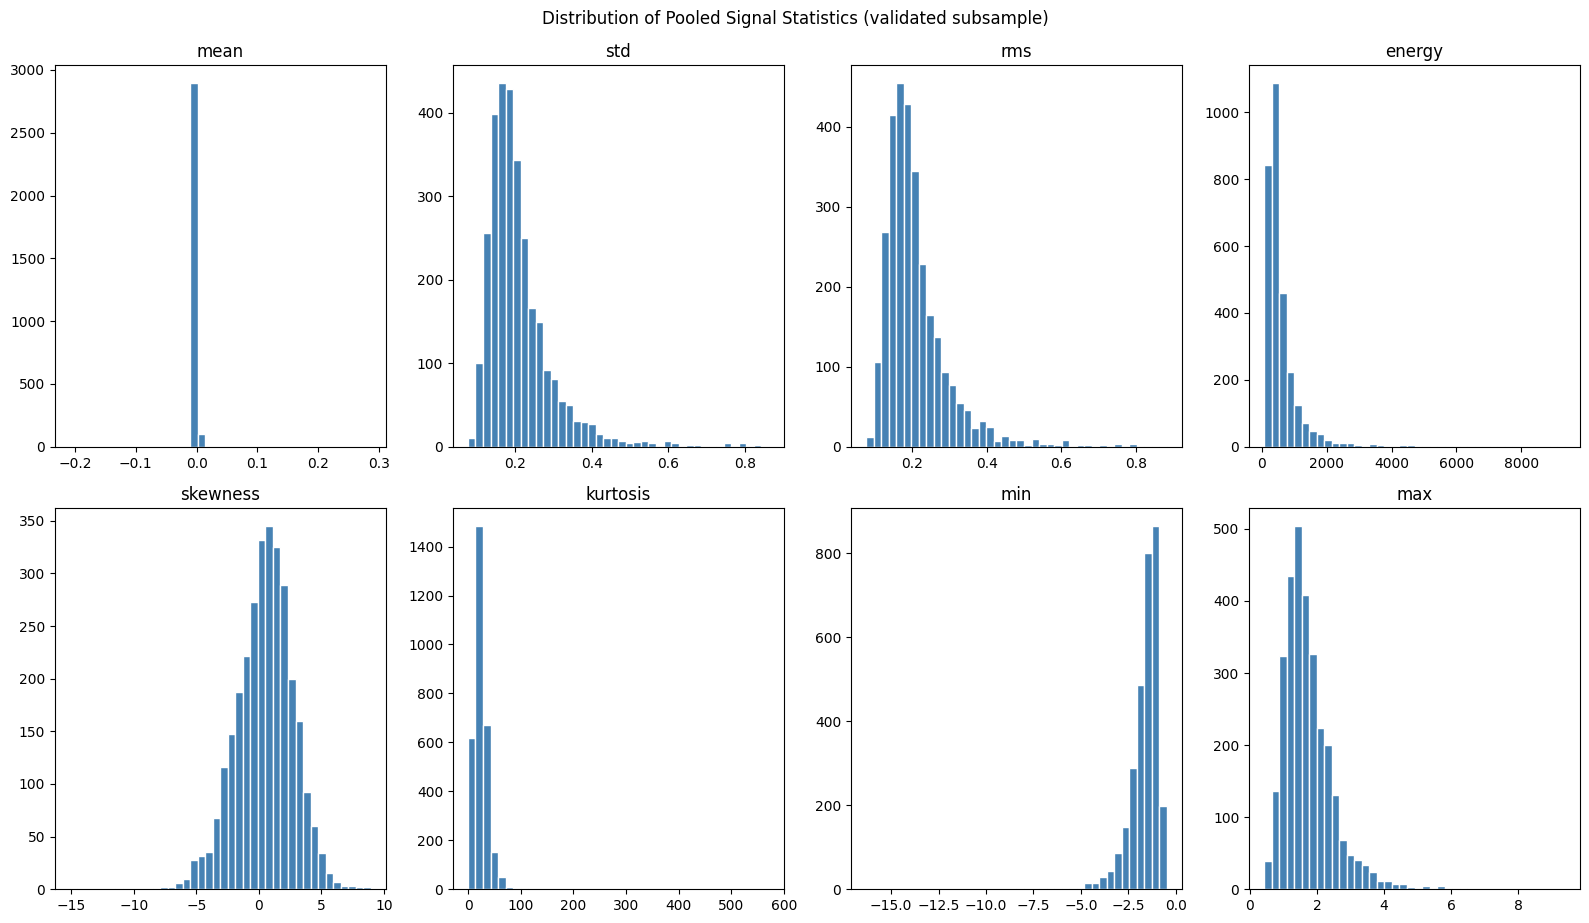

Fitted 'zscore' normalizer on 300 training-fold signals.


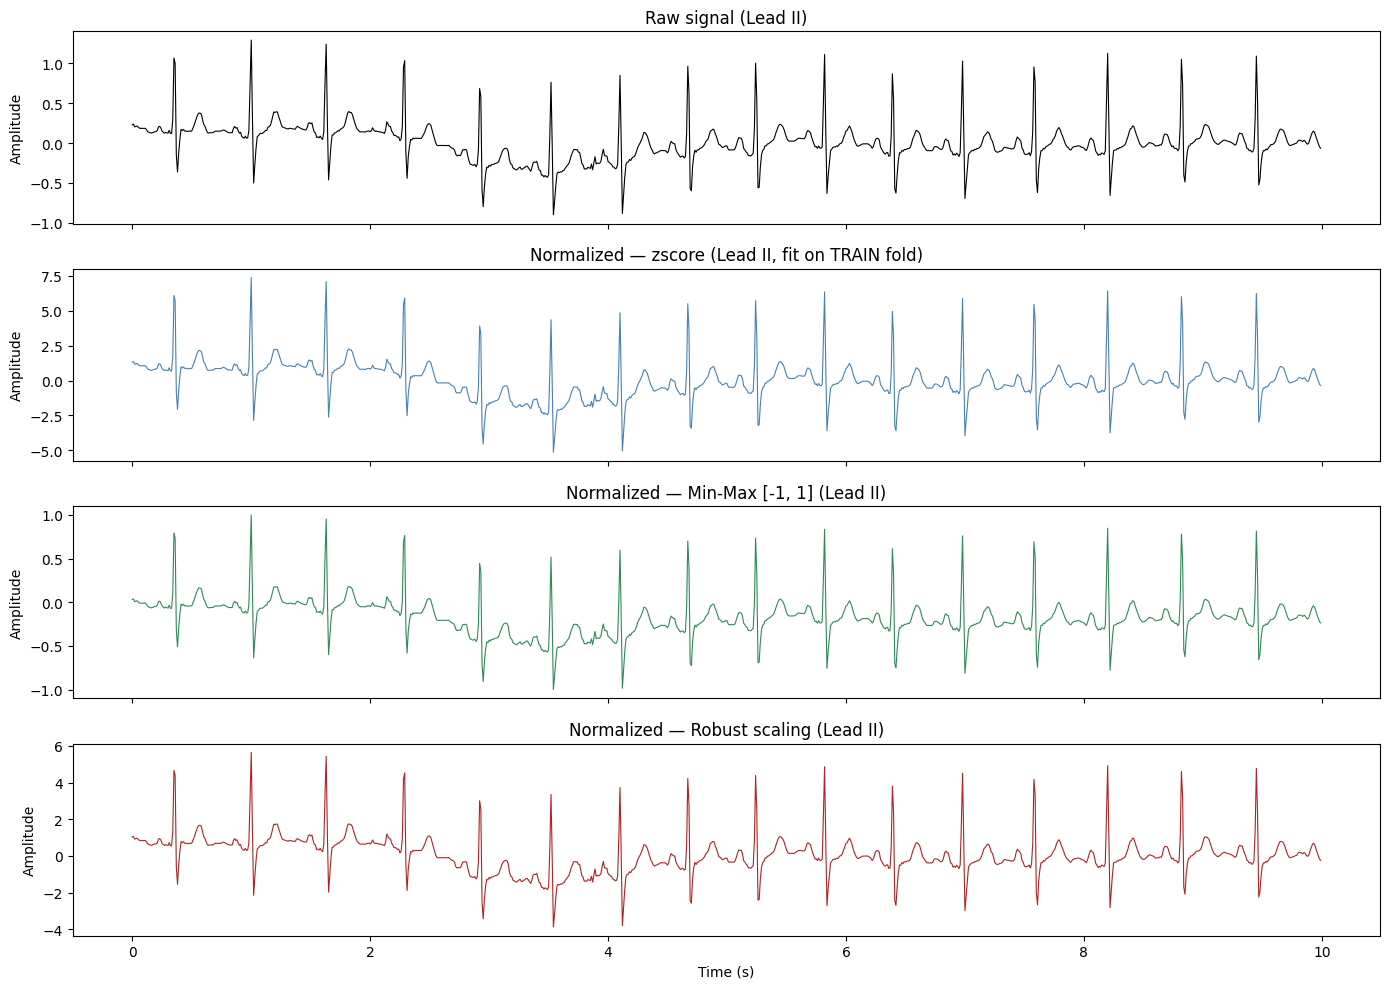

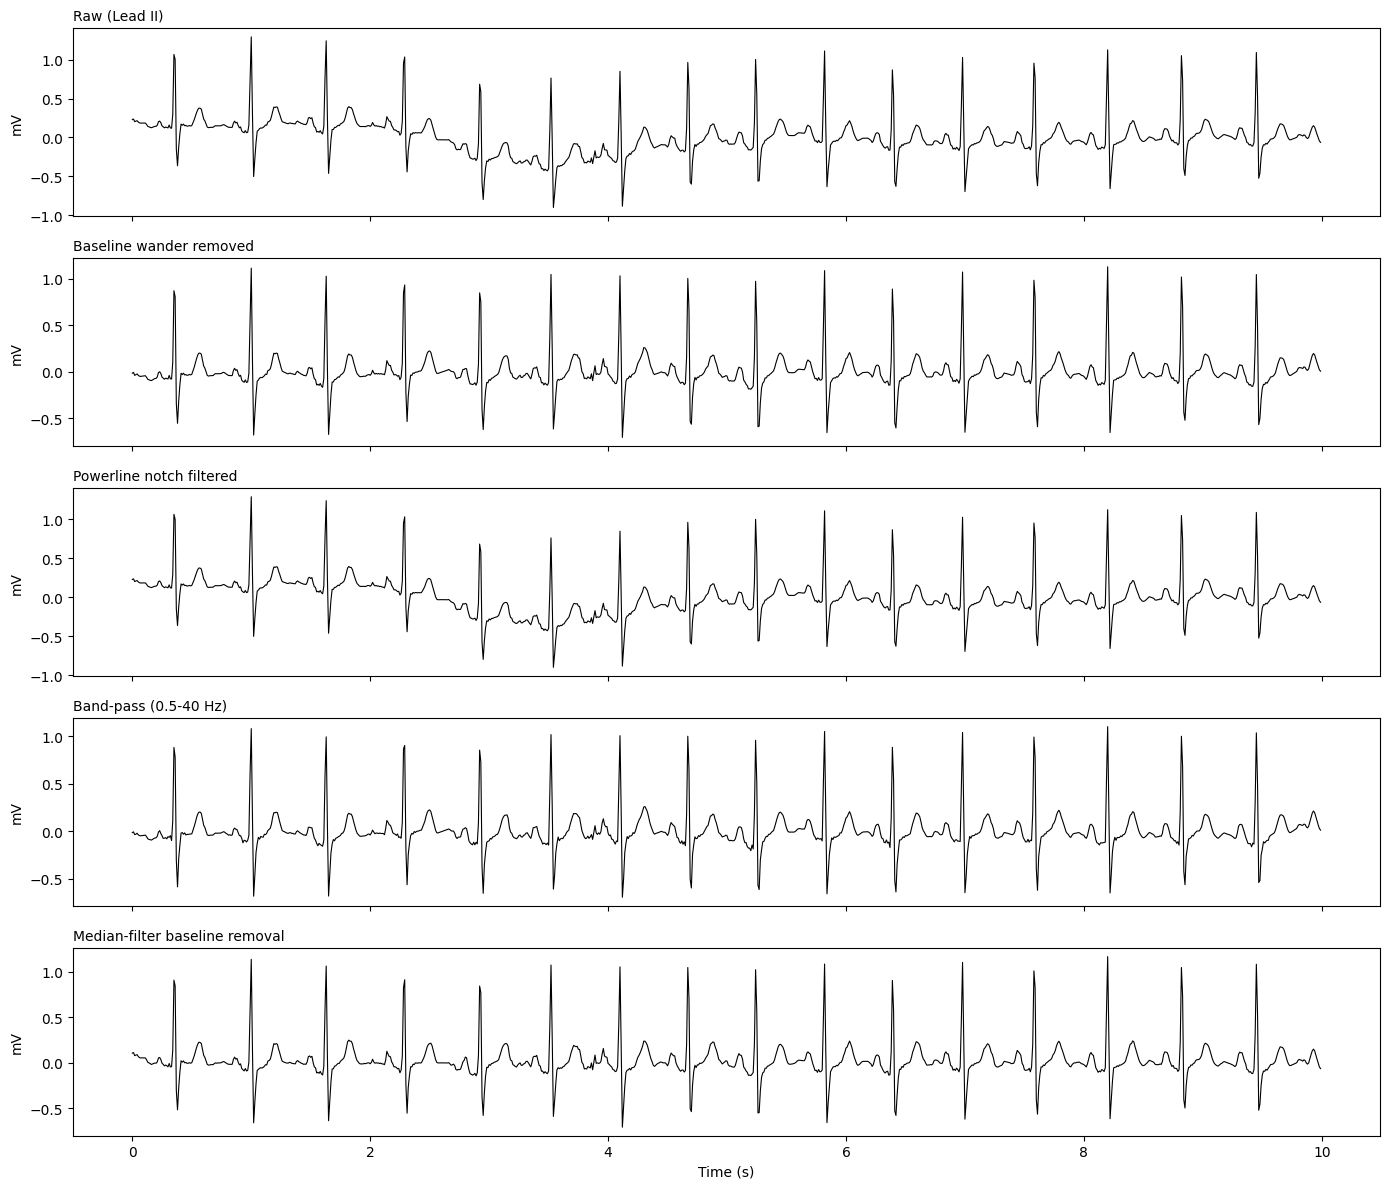

short input ( 800 samples) -> center: (12, 1000), random: (12, 1000)
exact input (1000 samples) -> center: (12, 1000), random: (12, 1000)
 long input (1300 samples) -> center: (12, 1000), random: (12, 1000)
ECGAugmentation initialized with ops: ['random_crop', 'time_stretch', 'random_time_shift', 'lead_dropout', 'random_masking', 'amplitude_scaling', 'random_scaling', 'gaussian_noise', 'random_jitter']


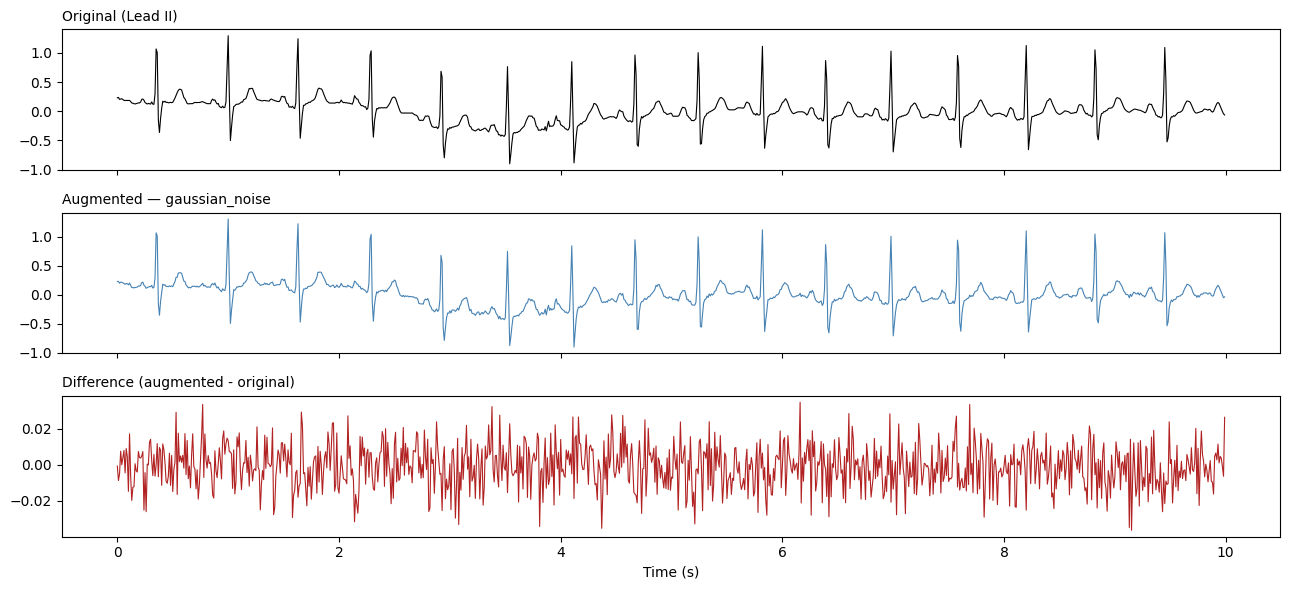

[gaussian_noise] Beneficial for robustness to electrode/EMG noise; excessive std can mask P/T waves.



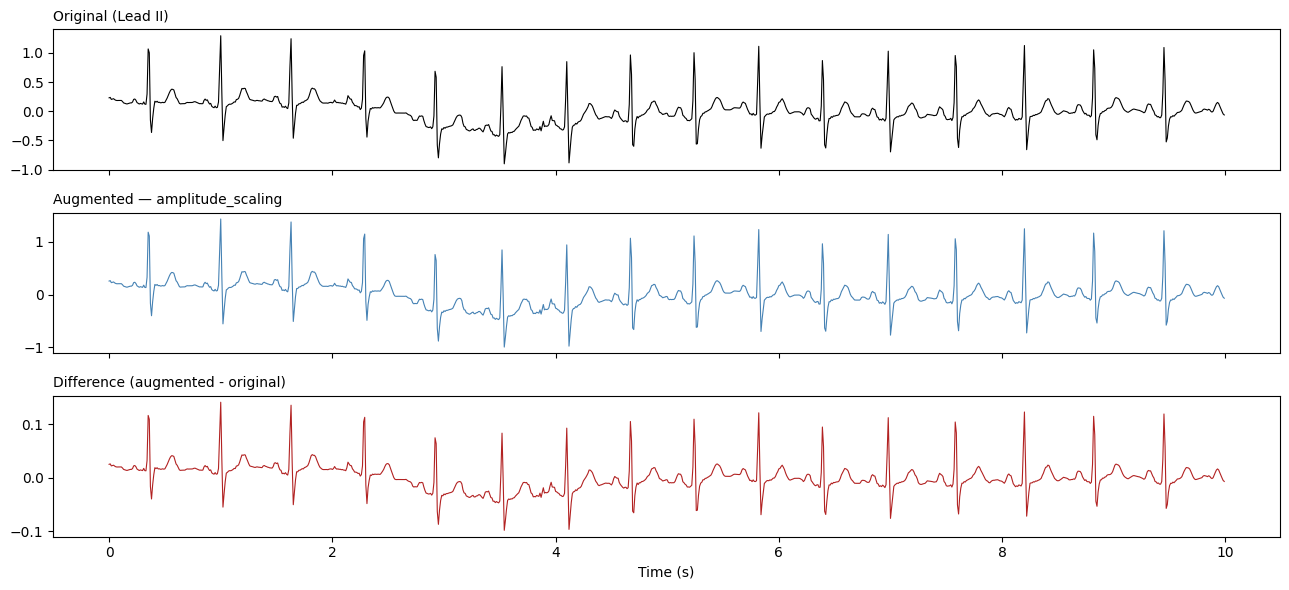

[amplitude_scaling] Beneficial for inter-patient/electrode-contact amplitude invariance.



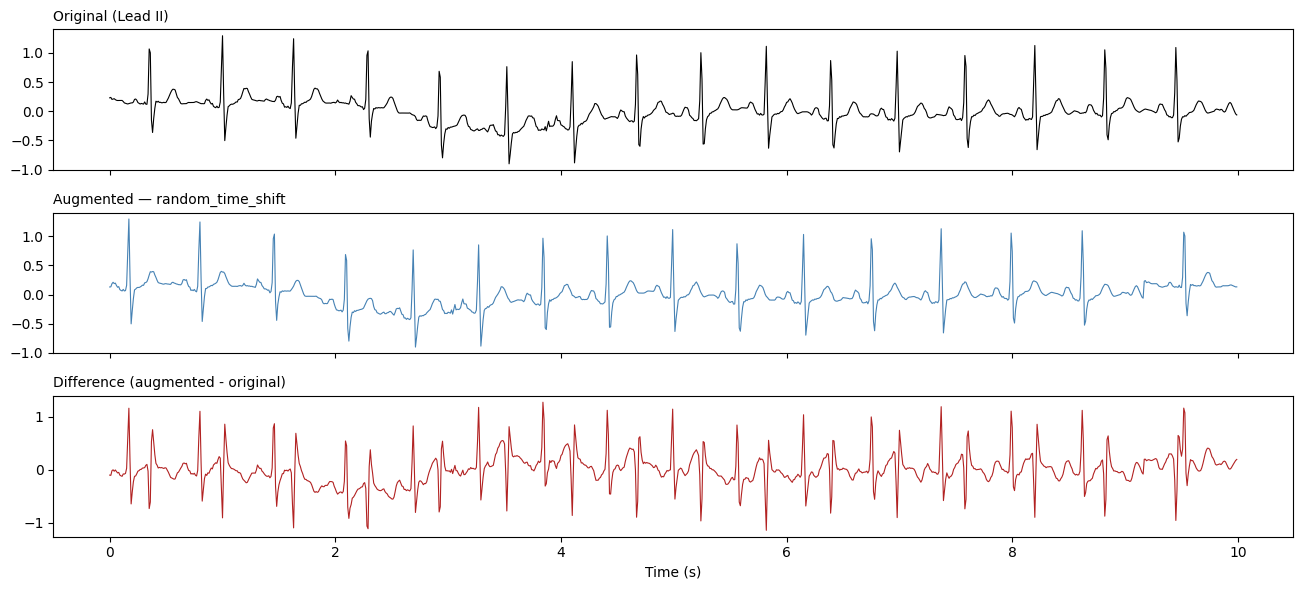

[random_time_shift] Beneficial for shift-invariant temporal features; keep shift small (<10%) to avoid clipping QRS out of frame.



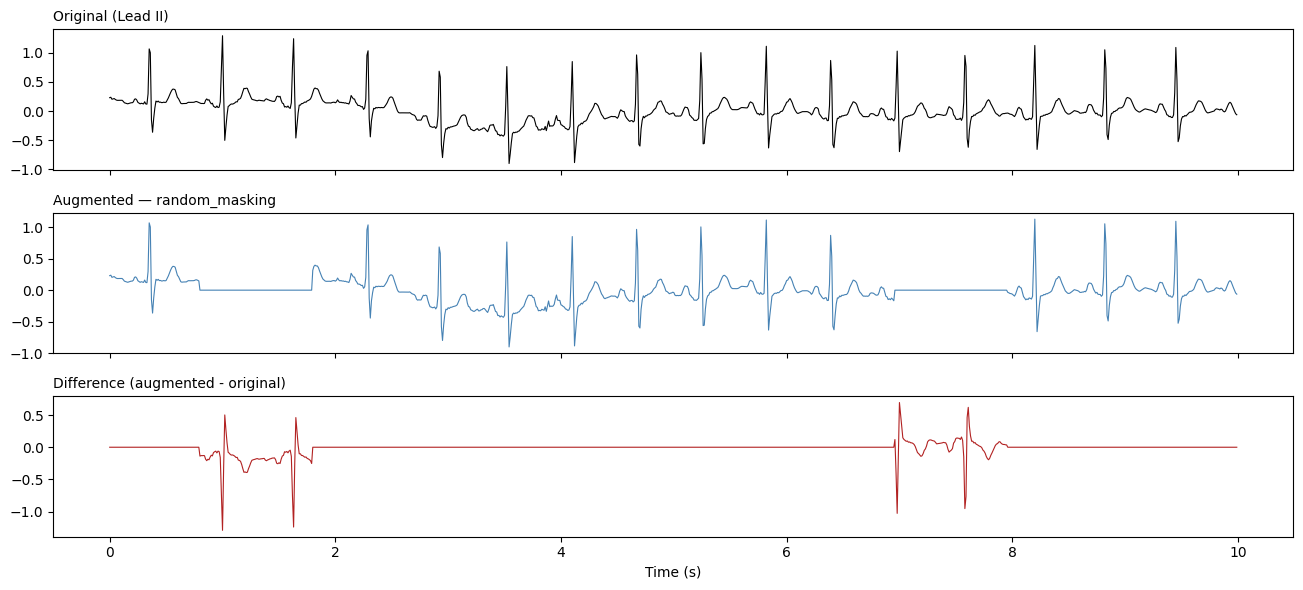

[random_masking] Beneficial as a lightweight cutout regularizer / SSL masked-reconstruction pretext signal.



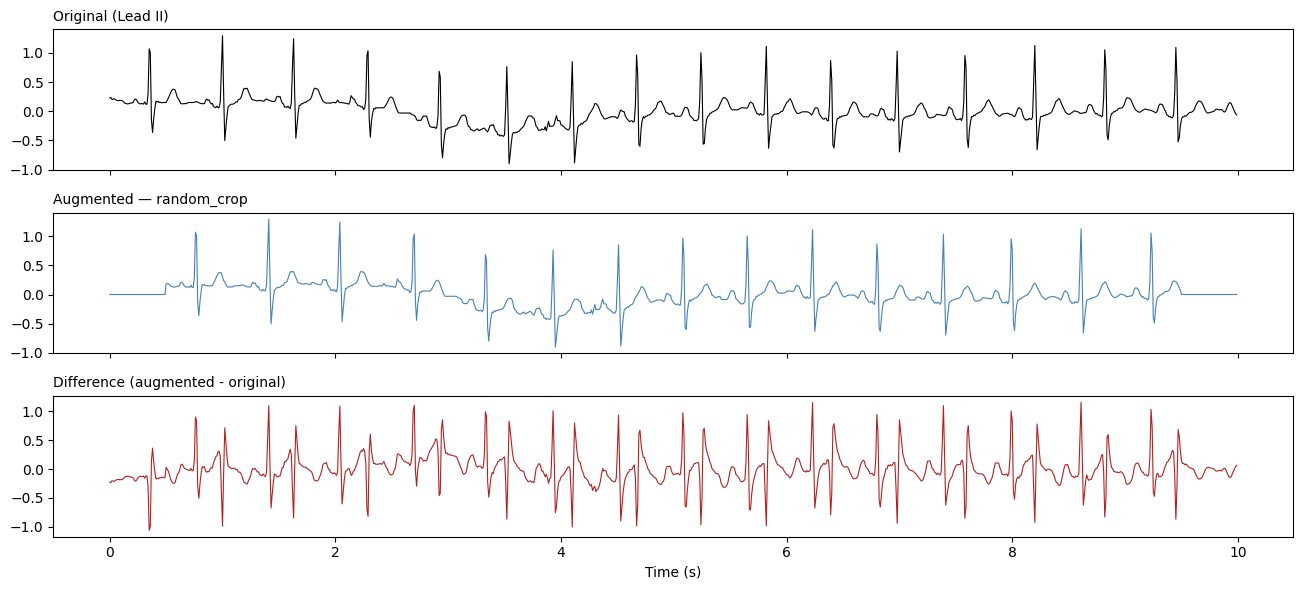

[random_crop] Beneficial for temporal-position invariance; avoid over-cropping which can remove full beats.



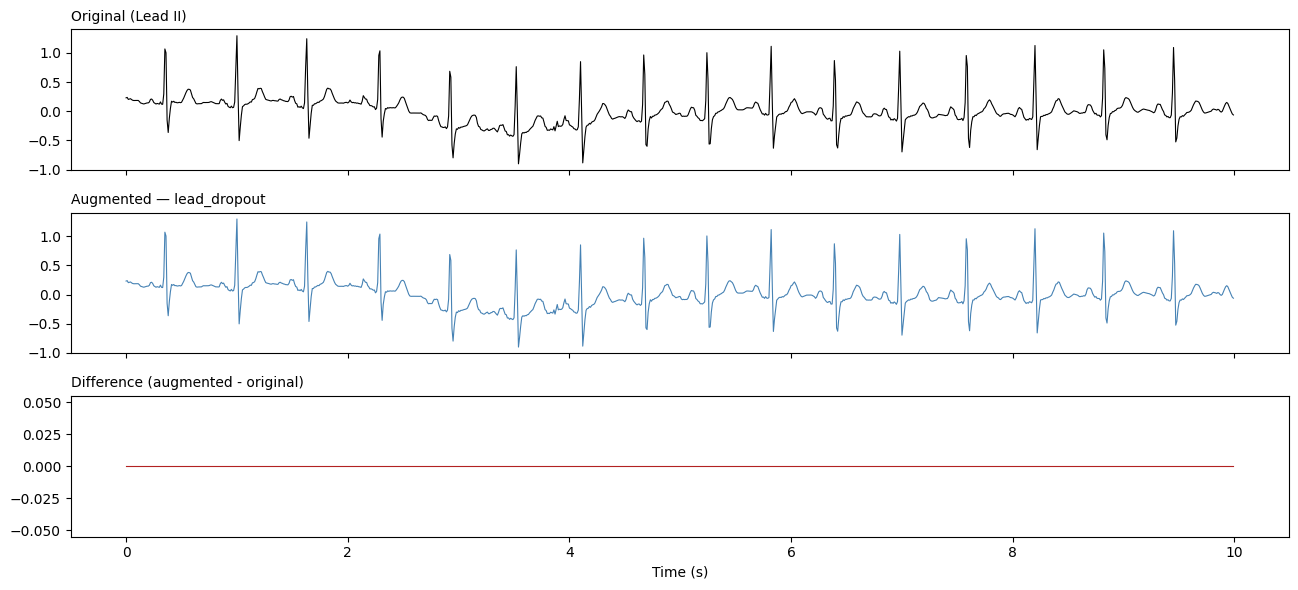

[lead_dropout] Beneficial for exploiting inter-lead redundancy (Einthoven/Goldberger); strong SSL pretext signal.



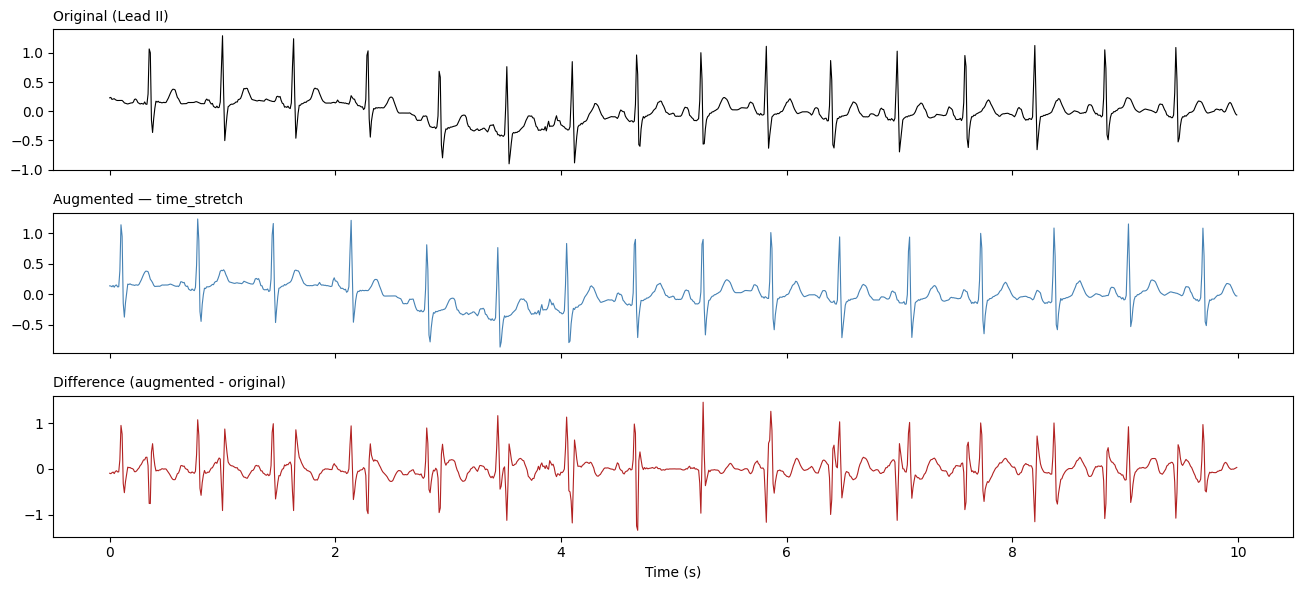

[time_stretch] Beneficial for heart-rate-variability robustness; extreme factors distort QRS morphology.



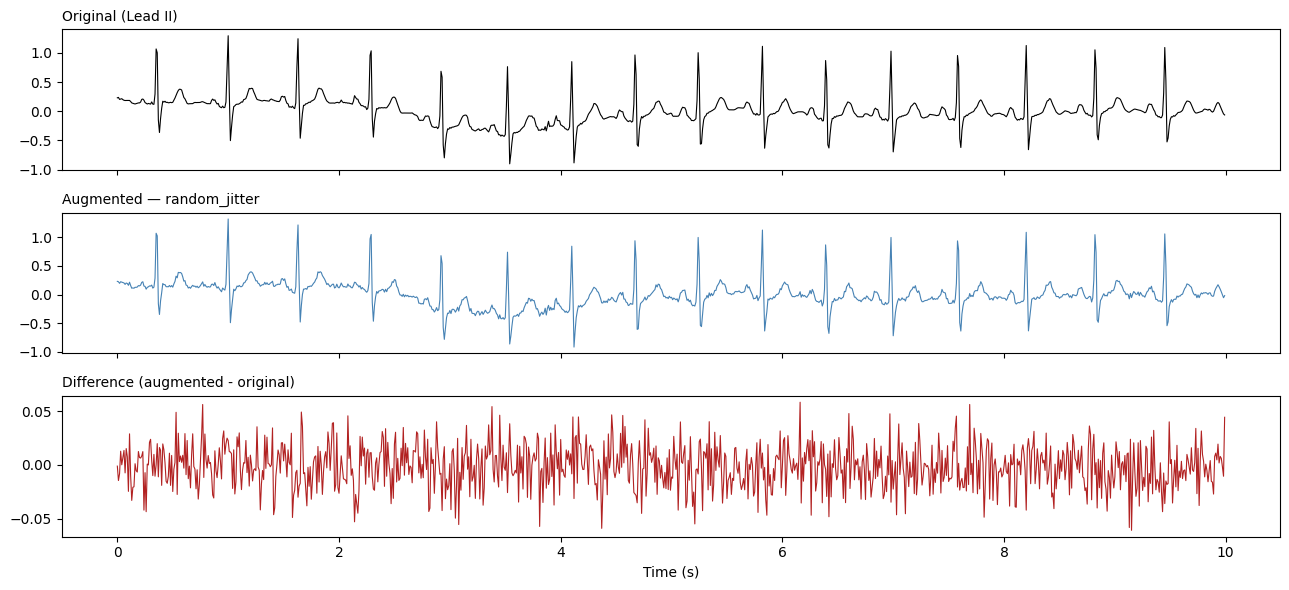

[random_jitter] Beneficial as a mild complement to gaussian_noise; small sigma keeps it a regularizer, not corruption.



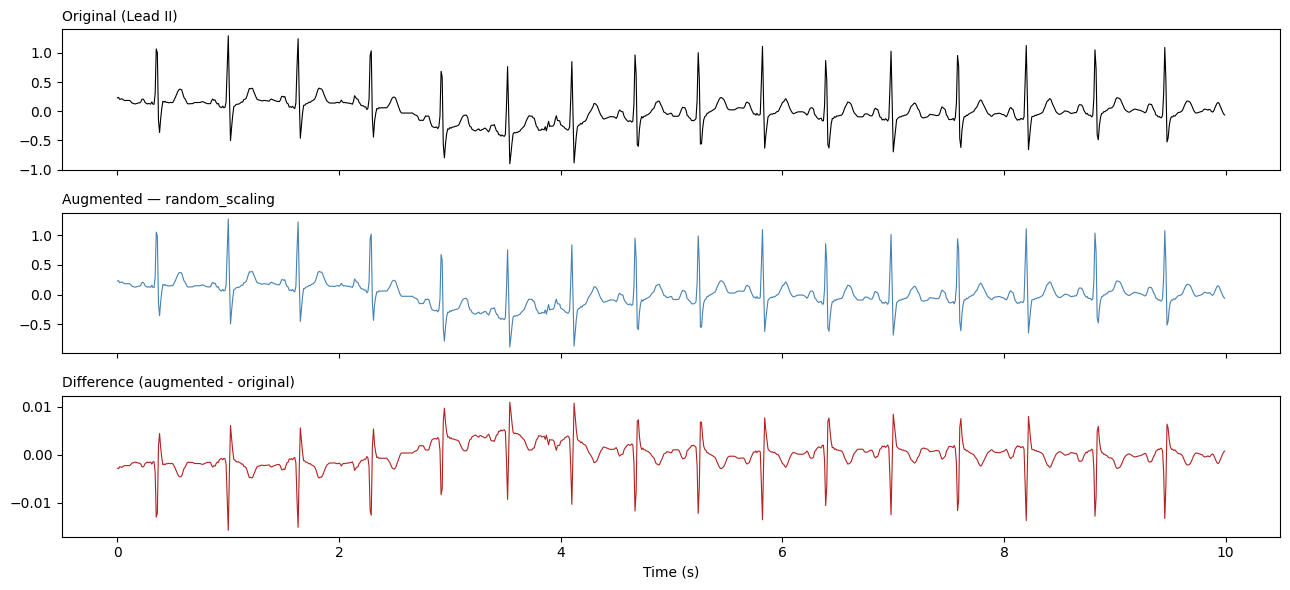

[random_scaling] Beneficial for per-lead gain-mismatch robustness (independent electrode calibration).

train:  17111 records
  val:   2156 records
 test:   2163 records

[PASS] No patient_id overlaps between train/val/test.

Per-split positive rate (%) by superclass:


,train,val,test
NORM,44.46,44.39,44.57
MI,25.65,25.23,25.57
STTC,24.50,24.77,24.18
CD,22.86,23.05,23.02
HYP,12.40,12.57,12.16



Max cross-split spread in positive rate: 0.59 pp (small values confirm the official stratification preserved class balance).
PTBXLDataset, PTBXLClassificationDataset, and PTBXLSSLDataset defined.
Sample 0 -> signal shape=(12, 1000), label shape=(5,), ecg_id=1
Smoke-test batch -> signals: (4, 12, 1000), labels: (4, 5)
Batch signals shape : (64, 12, 1000)   dtype=torch.float32
Batch labels  shape : (64, 5)    dtype=torch.float32
Example ecg_ids     : [14934, 11512, 13285, 12086, 763, 3388, 20276, 4862]
Example label rows  :
[[1. 0. 0. 0. 0.]
 [0. 1. 0. 0. 0.]
 [1. 0. 0. 1. 0.]
 [1. 0. 0. 0. 0.]
 [1. 0. 0. 0. 0.]]


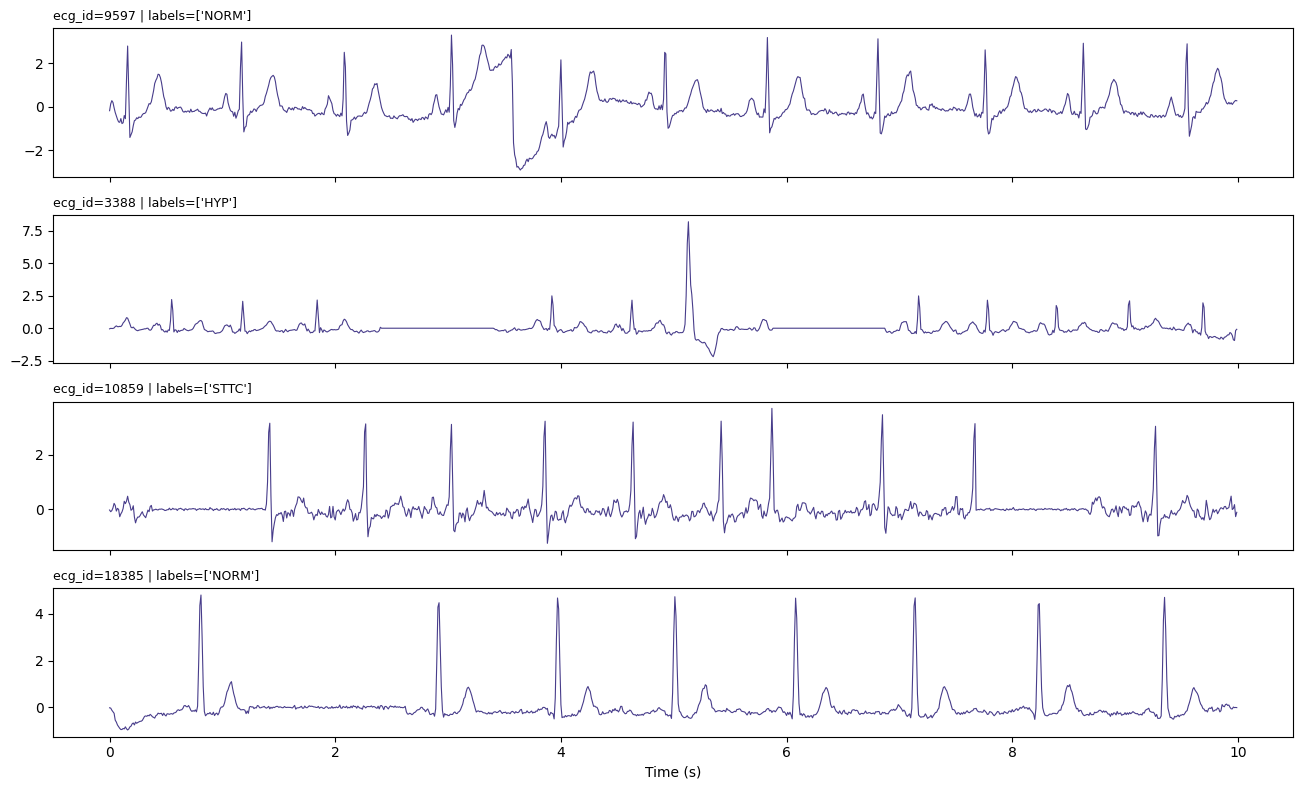

Dataset __getitem__ : 16.16 ms/item  (~61.9 items/sec, single process)
DataLoader batch    : 530.8 ms/batch  (~120.6 records/sec, num_workers=2)

CPU utilization (process): 0.0%
RAM usage (process)      : 1993.9 MB
System RAM usage         : 7.2%

GPU memory allocated : 0.0 MB
GPU memory reserved  : 0.0 MB
[NOTE] GPU utilization will be ~0% here since this notebook performs no forward/backward pass by design; measure it again in Notebook 03 once a model consumes these batches.


,check,passed
0,signal_shape_correct,True
1,label_shape_correct,True
2,no_patient_leakage,True
3,labels_are_binary,True
4,normalization_reasonable_scale,True
5,train_augmentation_is_stochastic,True
6,val_is_deterministic,True
7,no_nan_after_pipeline,True
8,no_inf_after_pipeline,True



[PASS] All quality-assurance checks passed.
Saved processed_metadata.csv     -> ./ptbxl_preprocessing_outputs/processed/processed_metadata.csv  (6723.7 KB)
Saved processed_labels.csv       -> ./ptbxl_preprocessing_outputs/processed/processed_labels.csv  (330.4 KB)
Saved dataset_statistics.csv     -> ./ptbxl_preprocessing_outputs/processed/dataset_statistics.csv  (0.2 KB)
Saved signal_statistics.csv      -> ./ptbxl_preprocessing_outputs/tables/signal_statistics.csv  (593.8 KB)
Saved quality_report.csv         -> ./ptbxl_preprocessing_outputs/tables/quality_report.csv  (183.2 KB)
Reusable API ready: get_train_loader, get_validation_loader, get_test_loader, get_ssl_loader, load_signal, normalize_signal, augment_signal.
train loader -> first tensor shape: (8, 12, 1000)
  val loader -> first tensor shape: (8, 12, 1000)
 test loader -> first tensor shape: (8, 12, 1000)
  ssl loader -> first tensor shape: (8, 12, 1000)

[PASS] Notebook 02 reusable API loaded: CONFIG, get_train_loader, get_va

In [5]:
# Section 4.1 — Locate and Execute Notebook 02 In-Namespace
# ---------------------------------------------------------------------------

import nbformat


def run_notebook_globals(notebook_path: str, target_globals: dict) -> None:
    """Execute every code cell of a notebook into `target_globals` (mirrors `%run` for .ipynb).

    Parameters
    ----------
    notebook_path : str
        Path to the `.ipynb` file to execute.
    target_globals : dict
        Namespace (typically `globals()`) that receives every name the
        notebook defines, so its Dataset classes / CONFIG / reusable API
        become directly usable in this notebook.
    """
    nb = nbformat.read(notebook_path, as_version=4)
    for i, cell in enumerate(nb.cells):
        if cell.cell_type != "code":
            continue
        try:
            exec(compile(cell.source, f"{notebook_path}#cell{i}", "exec"), target_globals)
        except Exception as exc:  # a stray display()/plot cell should never abort the import
            print(f"[WARN] cell {i} raised {exc.__class__.__name__}: {exc}")


def locate_pipeline_notebook(filename: str = "preprocessing-reusable-data-pipeline.ipynb",
                              slug_hint: str = "preprocess") -> str:
    """Find Notebook 02 under `/kaggle/input/` (or the local uploads folder as a fallback).

    Kaggle does NOT preserve a notebook's original filename when it is attached
    as a data source: it is materialized as
    `/kaggle/input/<notebook-slug>/__notebook__.ipynb`. This function therefore
    searches, in order: (1) the exact original filename, (2) any `.ipynb` whose
    *directory* name looks like the pipeline notebook's slug (covers the
    `__notebook__.ipynb` case), (3) any `.ipynb` whose own filename matches.

    Parameters
    ----------
    filename : str
        Original filename to look for first (exact match).
    slug_hint : str
        Substring to match against candidate directory/file names as a fallback
        (default catches slugs like "preprocessing-reusable-data-pipeline").

    Returns
    -------
    str
        Path to the located notebook file.

    Raises
    ------
    FileNotFoundError
        If no matching notebook can be found in any search location. The error
        message lists every `.ipynb` actually found under `/kaggle/input` to
        make misattachment obvious.
    """
    search_roots = ["/kaggle/input", "/mnt/user-data/uploads", ".", ".."]
    all_notebooks: List[str] = []
    for root in search_roots:
        if os.path.isdir(root):
            all_notebooks += glob.glob(os.path.join(root, "**", "*.ipynb"), recursive=True)

    # 1) Exact original filename.
    exact = [p for p in all_notebooks if os.path.basename(p) == filename]
    if exact:
        return exact[0]

    # 2) Slug match on the parent directory name (handles Kaggle's __notebook__.ipynb rename).
    by_dir = [p for p in all_notebooks if slug_hint in os.path.basename(os.path.dirname(p)).lower()]
    if by_dir:
        return by_dir[0]

    # 3) Slug match on the file's own name.
    by_name = [p for p in all_notebooks if slug_hint in os.path.basename(p).lower()]
    if by_name:
        return by_name[0]

    listing = "\n".join(f"  - {p}" for p in all_notebooks) or "  (no .ipynb files found at all)"
    raise FileNotFoundError(
        f"Could not locate Notebook 02 (looked for '{filename}' or a slug containing "
        f"'{slug_hint}').\n\n"
        "On Kaggle: open this notebook's editor -> right sidebar -> 'Add Input' -> "
        "'Notebooks' tab -> search for and attach a *saved/committed* version of "
        "'preprocessing-reusable-data-pipeline' -> rerun this cell.\n\n"
        f".ipynb files currently visible under /kaggle/input:\n{listing}"
    )


_pipeline_path = locate_pipeline_notebook()
print(f"Loading Notebook 02 reusable pipeline from: {_pipeline_path}")
run_notebook_globals(_pipeline_path, globals())

_required_api = ["CONFIG", "get_train_loader", "get_validation_loader", "get_test_loader",
                  "PTBXLClassificationDataset", "df_ptbxl", "label_matrix", "splits"]
_missing = [name for name in _required_api if name not in globals()]
if _missing:
    raise RuntimeError(f"Notebook 02 import incomplete — missing: {_missing}")
print("\n[PASS] Notebook 02 reusable API loaded:", ", ".join(_required_api))


In [6]:
# Section 4.2 — Build Train / Validation Loaders
# ---------------------------------------------------------------------------
# Re-synchronize the shared RNG seed against Notebook 02's CONFIG (single source
# of truth for RANDOM_SEED) now that it has been loaded, then build loaders at
# this notebook's own TRAIN_CONFIG.BATCH_SIZE.

TRAIN_CONFIG.RANDOM_SEED = CONFIG.RANDOM_SEED
set_global_seed(TRAIN_CONFIG.RANDOM_SEED, TRAIN_CONFIG.DETERMINISTIC)

train_loader = get_train_loader(batch_size=TRAIN_CONFIG.BATCH_SIZE, augment=True)
val_loader = get_validation_loader(batch_size=TRAIN_CONFIG.BATCH_SIZE)

print(f"Train records : {len(splits['train'])}   ({len(train_loader)} batches @ "
      f"batch_size={TRAIN_CONFIG.BATCH_SIZE})")
print(f"Val records   : {len(splits['val'])}   ({len(val_loader)} batches)")
print(f"Signal shape  : (N_LEADS={CONFIG.N_LEADS}, SIGNAL_LENGTH={CONFIG.SIGNAL_LENGTH})")
print(f"Classes       : {CONFIG.SUPERCLASSES}  (N_CLASSES={CONFIG.N_CLASSES}, multi-label)")

# Per-split positive-rate sanity check (already validated in Notebook 02; re-displayed for
# standalone-notebook traceability).
for name, ids in [("train", splits["train"]), ("val", splits["val"])]:
    rates = (label_matrix.loc[ids].sum() / len(ids) * 100).round(2)
    print(f"\n{name} positive rate (%):")
    print(rates.to_string())


Train records : 17111   (267 batches @ batch_size=64)
Val records   : 2156   (34 batches)
Signal shape  : (N_LEADS=12, SIGNAL_LENGTH=1000)
Classes       : ['NORM', 'MI', 'STTC', 'CD', 'HYP']  (N_CLASSES=5, multi-label)

train positive rate (%):
NORM    44.46
MI      25.65
STTC    24.50
CD      22.86
HYP     12.40

val positive rate (%):
NORM    44.39
MI      25.23
STTC    24.77
CD      23.05
HYP     12.57


## Section 5 — Data Verification

A final sanity pass on data actually flowing through the `DataLoader` before any model touches it:
one random ECG, one mini-batch, tensor shapes, dtypes, and a NaN/Inf sweep.


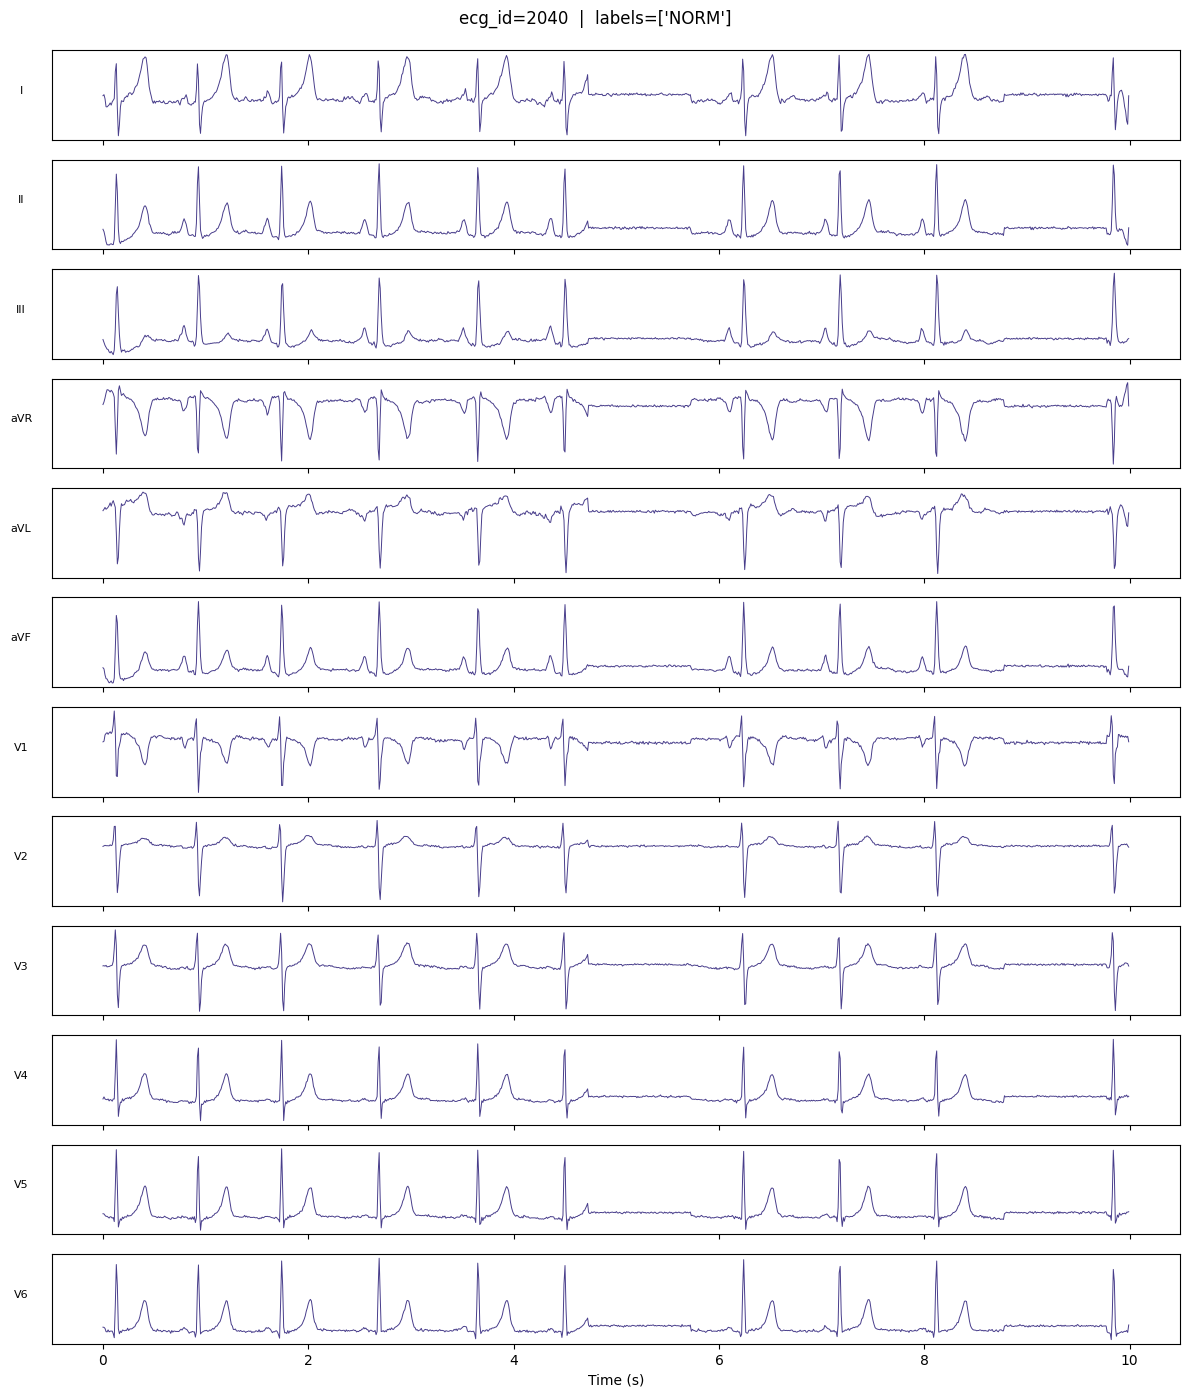

In [7]:
# Section 5.1 — Random ECG Visualization
# ---------------------------------------------------------------------------

_rng = np.random.default_rng(TRAIN_CONFIG.RANDOM_SEED)
_demo_idx = int(_rng.integers(0, len(train_loader.dataset)))
_demo_signal, _demo_label, _demo_id = train_loader.dataset[_demo_idx]

_t = np.arange(CONFIG.SIGNAL_LENGTH) / CONFIG.SAMPLING_RATE
fig, axes = plt.subplots(CONFIG.N_LEADS, 1, figsize=(12, 14), sharex=True)
for lead_idx, ax in enumerate(axes):
    ax.plot(_t, _demo_signal[lead_idx], linewidth=0.7, color="darkslateblue")
    ax.set_ylabel(CONFIG.LEAD_NAMES[lead_idx], rotation=0, labelpad=22, fontsize=8)
    ax.set_yticks([])
axes[-1].set_xlabel("Time (s)")
_present = [CONFIG.SUPERCLASSES[j] for j, v in enumerate(_demo_label) if v > 0.5] or ["(none mapped)"]
fig.suptitle(f"ecg_id={int(_demo_id)}  |  labels={_present}", y=0.995)
plt.tight_layout()
plt.savefig(os.path.join(TRAIN_CONFIG.FIGURES_DIR, "05_random_ecg.png"), dpi=150)
plt.show()


In [8]:
# Section 5.2 — Mini-Batch Shape / Type / NaN-Inf Verification
# ---------------------------------------------------------------------------

_batch_signals, _batch_labels, _batch_ids = next(iter(train_loader))

print(f"Signal batch  shape={tuple(_batch_signals.shape)}  dtype={_batch_signals.dtype}")
print(f"Label  batch  shape={tuple(_batch_labels.shape)}   dtype={_batch_labels.dtype}")
print(f"ID     batch  shape={tuple(_batch_ids.shape)}      dtype={_batch_ids.dtype}")

expected_signal_shape = (TRAIN_CONFIG.BATCH_SIZE, CONFIG.N_LEADS, CONFIG.SIGNAL_LENGTH)
expected_label_shape = (TRAIN_CONFIG.BATCH_SIZE, CONFIG.N_CLASSES)
assert _batch_signals.shape == expected_signal_shape or _batch_signals.shape[0] <= TRAIN_CONFIG.BATCH_SIZE, \
    f"Unexpected signal batch shape: {tuple(_batch_signals.shape)}"
assert _batch_labels.shape[1] == CONFIG.N_CLASSES, \
    f"Unexpected label width: {_batch_labels.shape[1]} != {CONFIG.N_CLASSES}"

n_nan = torch.isnan(_batch_signals).sum().item()
n_inf = torch.isinf(_batch_signals).sum().item()
label_range_ok = bool(((_batch_labels == 0) | (_batch_labels == 1)).all())

print(f"\nNaN count in signals   : {n_nan}")
print(f"Inf count in signals   : {n_inf}")
print(f"Labels strictly binary : {label_range_ok}")

assert n_nan == 0, "NaN values found in a training batch."
assert n_inf == 0, "Inf values found in a training batch."
assert label_range_ok, "Label tensor contains values outside {0, 1}."
print("\n[PASS] Batch shape, dtype, and NaN/Inf verification.")


Signal batch  shape=(64, 12, 1000)  dtype=torch.float32
Label  batch  shape=(64, 5)   dtype=torch.float32
ID     batch  shape=(64,)      dtype=torch.int64

NaN count in signals   : 0
Inf count in signals   : 0
Labels strictly binary : True

[PASS] Batch shape, dtype, and NaN/Inf verification.


## Section 5.3 — Class Imbalance: Positive-Class Weights (v2 new)

Per-class positive rates on the training fold (NORM 44.5%, MI 25.6%, STTC 24.5%, CD 22.9%,
**HYP only 12.4%**) mean a plain, unweighted `BCEWithLogitsLoss` under-penalizes misses on the
minority classes — the loss can be driven down mostly by getting NORM/MI right. `pos_weight`
(one scalar per class, `= (N_negative / N_positive)`, clipped to `TRAIN_CONFIG.POS_WEIGHT_MAX` to
avoid destabilizing gradients on the rarest class) rescales the positive-example loss term per
class so a missed HYP costs proportionally as much as a missed NORM.


In [9]:
# Section 5.3 — Compute per-class pos_weight from the training split
# ---------------------------------------------------------------------------

_train_label_matrix = label_matrix.loc[splits["train"]]
_pos_rate = _train_label_matrix.mean()          # fraction of positives per class
_pos_weight_raw = (1.0 - _pos_rate) / _pos_rate.clip(lower=1e-6)
_pos_weight_clipped = _pos_weight_raw.clip(upper=TRAIN_CONFIG.POS_WEIGHT_MAX)

pos_weight_table = pd.DataFrame({
    "positive_rate_pct": (_pos_rate * 100).round(2),
    "raw_pos_weight": _pos_weight_raw.round(3),
    "clipped_pos_weight": _pos_weight_clipped.round(3),
})
display(pos_weight_table)

pos_weight_tensor = torch.tensor(
    _pos_weight_clipped[CONFIG.SUPERCLASSES].values, dtype=torch.float32, device=TRAIN_CONFIG.DEVICE,
)
print(f"\npos_weight tensor (order={CONFIG.SUPERCLASSES}): {pos_weight_tensor.tolist()}")


,positive_rate_pct,raw_pos_weight,clipped_pos_weight
NORM,44.46,1.249,1.249
MI,25.65,2.899,2.899
STTC,24.50,3.081,3.081
CD,22.86,3.374,3.374
HYP,12.40,7.067,7.067



pos_weight tensor (order=['NORM', 'MI', 'STTC', 'CD', 'HYP']): [1.249375581741333, 2.8986101150512695, 3.0808489322662354, 3.3739774227142334, 7.067420959472656]


## Section 6 — Build Mamba Model (v2 — bidirectional + attention pooling)

```
Input (B, N_LEADS, T)
      │  transpose -> (B, T, N_LEADS)
      ▼
Linear Projection  (N_LEADS -> EMBED_DIM)
      ▼
Stack of BidirectionalMambaBlock × N_MAMBA_LAYERS   (pre-norm, residual)
      │     each block: forward mamba(x) + backward mamba(flip(x)) -> concat -> Linear -> dropout -> residual add
      ▼
LayerNorm
      ▼
Mean-Attention Pooling  (mean over time  ‖  learned-attention-weighted sum over time)
      ▼
Dropout
      ▼
Classification Head  (Linear -> GELU -> Dropout -> Linear)
      ▼
Logits (B, N_CLASSES)
```

**`BidirectionalMambaBlock`** runs two independent `mamba_ssm.Mamba` instances — one over the
sequence as given, one over the time-reversed sequence (re-flipped back afterward) — concatenates
their outputs along the feature dimension, and projects back down to `d_model` with a `Linear`
layer before the residual add. This roughly doubles the per-block Mamba compute but keeps the
overall complexity linear in sequence length, and lets every position's representation depend on
context from both directions — appropriate since ECG classification sees the whole 10s window at
once (unlike autoregressive generation, which is unidirectional by necessity).

**`AttentionPool`** learns a scalar importance score per timestep (via a small `Linear -> tanh ->
Linear` scorer, followed by a softmax over time) and returns the softmax-weighted sum of the
sequence. This is concatenated with plain mean-pooling before the classification head, so the model
can use *both* a global average (v1's only pooling signal) *and* a learned, content-dependent
emphasis on the timesteps that matter most for each recording (e.g. a single abnormal QRS complex),
which mean-pooling alone would dilute.


In [10]:
# Section 6.1 — BidirectionalMambaBlock, AttentionPool, ClassificationHead, MambaClassifier
# ---------------------------------------------------------------------------

class BidirectionalMambaBlock(nn.Module):
    """A pre-norm, residual Mamba block that scans both directions and concatenates.

    Parameters
    ----------
    d_model : int
        Residual-stream / embedding dimension.
    d_state : int
        SSM state expansion factor (official `mamba_ssm.Mamba` parameter).
    d_conv : int
        Local causal-convolution kernel width.
    expand : int
        Inner block expansion factor.
    dropout : float
        Dropout probability applied to the block's output before the residual add.
    bidirectional : bool
        If True, run a second Mamba over the time-reversed sequence and concatenate
        + project back to `d_model`. If False, behaves like the v1 unidirectional block.
    """

    def __init__(self, d_model: int, d_state: int, d_conv: int, expand: int, dropout: float,
                 bidirectional: bool = True):
        super().__init__()
        self.bidirectional = bidirectional
        self.norm = nn.LayerNorm(d_model)
        self.mamba_fwd = Mamba(d_model=d_model, d_state=d_state, d_conv=d_conv, expand=expand)
        if bidirectional:
            self.mamba_bwd = Mamba(d_model=d_model, d_state=d_state, d_conv=d_conv, expand=expand)
            self.merge = nn.Linear(2 * d_model, d_model)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        """Apply pre-norm -> (bi-)Mamba -> dropout -> residual add.

        Parameters
        ----------
        x : torch.Tensor
            Shape `(batch, length, d_model)`.

        Returns
        -------
        torch.Tensor
            Same shape as `x`.
        """
        residual = x
        x = self.norm(x)
        out_fwd = self.mamba_fwd(x)
        if self.bidirectional:
            out_bwd = self.mamba_bwd(torch.flip(x, dims=[1]))
            out_bwd = torch.flip(out_bwd, dims=[1])
            out = self.merge(torch.cat([out_fwd, out_bwd], dim=-1))
        else:
            out = out_fwd
        out = self.dropout(out)
        return residual + out


class AttentionPool(nn.Module):
    """Learned additive attention pooling over the time dimension.

    Parameters
    ----------
    d_model : int
        Feature dimension of the sequence to pool.
    hidden_dim : int
        Hidden width of the attention scorer MLP.
    """

    def __init__(self, d_model: int, hidden_dim: int = 64):
        super().__init__()
        self.scorer = nn.Sequential(
            nn.Linear(d_model, hidden_dim),
            nn.Tanh(),
            nn.Linear(hidden_dim, 1),
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        """Pool `(batch, length, d_model)` -> `(batch, d_model)` via a softmax-weighted sum."""
        scores = self.scorer(x)                       # (B, T, 1)
        weights = torch.softmax(scores, dim=1)         # (B, T, 1), sums to 1 over time
        return (x * weights).sum(dim=1)                # (B, d_model)


class ClassificationHead(nn.Module):
    """Two-layer MLP classification head producing raw (pre-sigmoid) logits.

    Parameters
    ----------
    in_dim : int
        Input feature dimension (pooled backbone width).
    hidden_dim : int
        Hidden-layer width.
    n_classes : int
        Number of output logits (one per diagnostic superclass).
    dropout : float
        Dropout probability applied after the hidden activation.
    """

    def __init__(self, in_dim: int, hidden_dim: int, n_classes: int, dropout: float):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_dim, hidden_dim),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim, n_classes),
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        """Map pooled features to class logits. `x`: `(batch, in_dim)` -> `(batch, n_classes)`."""
        return self.net(x)


class MambaClassifier(nn.Module):
    """Full supervised Mamba classifier: input projection -> bi-Mamba stack -> pooled head.

    Parameters
    ----------
    n_leads : int
        Number of input channels (ECG leads).
    n_classes : int
        Number of output classes (multi-label).
    embed_dim : int
        Mamba residual-stream width (`d_model`).
    hidden_dim : int
        Classification-head hidden width.
    n_layers : int
        Number of stacked `BidirectionalMambaBlock`s.
    d_state, d_conv, expand : int
        Forwarded to every `mamba_ssm.Mamba` instance.
    dropout : float
        Dropout probability used in both the backbone blocks and the head.
    bidirectional : bool
        Whether Mamba blocks scan both directions (v2 default: True).
    pooling : str
        One of `{"mean", "mean_attention"}`. `"mean_attention"` (v2 default) concatenates
        plain mean-pooling with learned attention-pooling before the head.
    """

    def __init__(self, n_leads: int, n_classes: int, embed_dim: int, hidden_dim: int,
                 n_layers: int, d_state: int, d_conv: int, expand: int, dropout: float,
                 bidirectional: bool = True, pooling: str = "mean_attention"):
        super().__init__()
        if pooling not in {"mean", "mean_attention"}:
            raise ValueError(f"pooling must be 'mean' or 'mean_attention', got {pooling!r}")
        self.pooling = pooling

        self.input_proj = nn.Linear(n_leads, embed_dim)
        self.blocks = nn.ModuleList([
            BidirectionalMambaBlock(embed_dim, d_state, d_conv, expand, dropout, bidirectional)
            for _ in range(n_layers)
        ])
        self.final_norm = nn.LayerNorm(embed_dim)
        self.dropout = nn.Dropout(dropout)

        if pooling == "mean_attention":
            self.attn_pool = AttentionPool(embed_dim)
            head_in_dim = embed_dim * 2   # mean ‖ attention-pooled
        else:
            self.attn_pool = None
            head_in_dim = embed_dim

        self.head = ClassificationHead(head_in_dim, hidden_dim, n_classes, dropout)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        """Classify a batch of ECG signals.

        Parameters
        ----------
        x : torch.Tensor
            Shape `(batch, n_leads, length)` — the raw preprocessed signal layout
            produced by Notebook 02's `PTBXLClassificationDataset`.

        Returns
        -------
        torch.Tensor
            Logits of shape `(batch, n_classes)` (apply `sigmoid` for probabilities).
        """
        x = x.transpose(1, 2)          # (B, N_LEADS, T) -> (B, T, N_LEADS)
        x = self.input_proj(x)         # -> (B, T, embed_dim)
        for block in self.blocks:
            x = block(x)
        x = self.final_norm(x)

        mean_pooled = x.mean(dim=1)    # (B, embed_dim)
        if self.pooling == "mean_attention":
            attn_pooled = self.attn_pool(x)              # (B, embed_dim)
            pooled = torch.cat([mean_pooled, attn_pooled], dim=-1)  # (B, 2*embed_dim)
        else:
            pooled = mean_pooled

        pooled = self.dropout(pooled)
        return self.head(pooled)       # -> (B, n_classes)


In [11]:
# Section 6.2 — Instantiate and Smoke-Test the Model
# ---------------------------------------------------------------------------

model = MambaClassifier(
    n_leads=CONFIG.N_LEADS,
    n_classes=CONFIG.N_CLASSES,
    embed_dim=TRAIN_CONFIG.EMBED_DIM,
    hidden_dim=TRAIN_CONFIG.HIDDEN_DIM,
    n_layers=TRAIN_CONFIG.N_MAMBA_LAYERS,
    d_state=TRAIN_CONFIG.D_STATE,
    d_conv=TRAIN_CONFIG.D_CONV,
    expand=TRAIN_CONFIG.EXPAND,
    dropout=TRAIN_CONFIG.DROPOUT,
    bidirectional=TRAIN_CONFIG.BIDIRECTIONAL,
    pooling=TRAIN_CONFIG.POOLING,
).to(TRAIN_CONFIG.DEVICE)

n_params = sum(p.numel() for p in model.parameters())
n_trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Total parameters     : {n_params:,}")
print(f"Trainable parameters : {n_trainable:,}")

model.eval()
with torch.no_grad():
    _probe = torch.randn(4, CONFIG.N_LEADS, CONFIG.SIGNAL_LENGTH, device=TRAIN_CONFIG.DEVICE)
    _out = model(_probe)
print(f"\nSmoke test  input={tuple(_probe.shape)}  ->  output={tuple(_out.shape)}")
assert _out.shape == (4, CONFIG.N_CLASSES), "Model output shape mismatch."
print("[PASS] Forward pass shape check.")
model.train()


Total parameters     : 18,117,638
Trainable parameters : 18,117,638

Smoke test  input=(4, 12, 1000)  ->  output=(4, 5)
[PASS] Forward pass shape check.


MambaClassifier(
  (input_proj): Linear(in_features=12, out_features=384, bias=True)
  (blocks): ModuleList(
    (0-7): 8 x BidirectionalMambaBlock(
      (norm): LayerNorm((384,), eps=1e-05, elementwise_affine=True)
      (mamba_fwd): Mamba(
        (in_proj): Linear(in_features=384, out_features=1536, bias=False)
        (conv1d): Conv1d(768, 768, kernel_size=(4,), stride=(1,), padding=(3,), groups=768)
        (act): SiLU()
        (x_proj): Linear(in_features=768, out_features=56, bias=False)
        (dt_proj): Linear(in_features=24, out_features=768, bias=True)
        (out_proj): Linear(in_features=768, out_features=384, bias=False)
      )
      (mamba_bwd): Mamba(
        (in_proj): Linear(in_features=384, out_features=1536, bias=False)
        (conv1d): Conv1d(768, 768, kernel_size=(4,), stride=(1,), padding=(3,), groups=768)
        (act): SiLU()
        (x_proj): Linear(in_features=768, out_features=56, bias=False)
        (dt_proj): Linear(in_features=24, out_features=768, 

## Section 7 — Training Components (v2 — weighted loss + warmup/cosine)

- **Loss** — `BCEWithLogitsLoss(pos_weight=...)` (v2: class-weighted, see Section 5.3) with
  **label smoothing** (v2 new) applied to the training targets only (validation loss/AUROC are
  always computed against the true, un-smoothed labels).
- **Optimizer** — `AdamW`.
- **Scheduler** — v2: **linear warmup** (`TRAIN_CONFIG.WARMUP_EPOCHS`) **then cosine annealing**
  over the remaining epochs, via `SequentialLR`. v1 used plain cosine from epoch 1, which the v2
  attention-pooling parameters (freshly initialized, unlike the rest of the pretrained-shape
  backbone) benefit from easing into more gradually.
- **Mixed precision** — `torch.amp.autocast` + `GradScaler` for T4 Tensor Core throughput.
- **Gradient clipping** — global-norm clipping before every optimizer step.
- **Early stopping** — monitors validation macro-AUROC with patience-based stopping (patience
  tightened to 5 in v2; see Section 3).


In [12]:
# Section 7 — Training Components
# ---------------------------------------------------------------------------

def make_criterion(pos_weight: Optional[torch.Tensor], label_smoothing: float):
    """Build the (class-weighted) BCE loss, with optional label smoothing applied by the caller.

    Parameters
    ----------
    pos_weight : torch.Tensor or None
        Per-class positive weight forwarded to `BCEWithLogitsLoss`. None disables weighting
        (reproduces v1 behavior).
    label_smoothing : float
        Stored on the returned object for the Trainer to apply to *training* targets only;
        `BCEWithLogitsLoss` itself has no native label-smoothing argument for multi-label targets.

    Returns
    -------
    nn.BCEWithLogitsLoss
        With `.label_smoothing` set as an extra attribute for the Trainer to read.
    """
    criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
    criterion.label_smoothing = label_smoothing
    return criterion


def smooth_labels(labels: torch.Tensor, smoothing: float) -> torch.Tensor:
    """Soften hard {0, 1} multi-label targets: `0 -> smoothing/2`, `1 -> 1 - smoothing/2`."""
    if smoothing <= 0:
        return labels
    return labels * (1.0 - smoothing) + 0.5 * smoothing


criterion = make_criterion(
    pos_weight=pos_weight_tensor if TRAIN_CONFIG.USE_POS_WEIGHT else None,
    label_smoothing=TRAIN_CONFIG.LABEL_SMOOTHING,
)

optimizer = AdamW(
    model.parameters(),
    lr=TRAIN_CONFIG.LEARNING_RATE,
    weight_decay=TRAIN_CONFIG.WEIGHT_DECAY,
)

# v2: linear warmup for WARMUP_EPOCHS, then cosine annealing over the remaining epochs.
_warmup_epochs = max(1, min(TRAIN_CONFIG.WARMUP_EPOCHS, TRAIN_CONFIG.EPOCHS - 1))
_cosine_epochs = TRAIN_CONFIG.EPOCHS - _warmup_epochs
_warmup_scheduler = LinearLR(optimizer, start_factor=0.1, end_factor=1.0, total_iters=_warmup_epochs)
_cosine_scheduler = CosineAnnealingLR(optimizer, T_max=_cosine_epochs, eta_min=TRAIN_CONFIG.MIN_LR)
scheduler = SequentialLR(
    optimizer, schedulers=[_warmup_scheduler, _cosine_scheduler], milestones=[_warmup_epochs],
)

scaler = torch.amp.GradScaler(
    device="cuda", enabled=(TRAIN_CONFIG.MIXED_PRECISION and torch.cuda.is_available())
)

val_auroc_metric = MultilabelAUROC(num_labels=CONFIG.N_CLASSES, average="macro").to(TRAIN_CONFIG.DEVICE)
train_auroc_metric = MultilabelAUROC(num_labels=CONFIG.N_CLASSES, average="macro").to(TRAIN_CONFIG.DEVICE)


class EarlyStopping:
    """Patience-based early stopping on a maximized validation metric (e.g. macro-AUROC).

    Parameters
    ----------
    patience : int
        Number of consecutive non-improving epochs tolerated before stopping.
    min_delta : float
        Minimum improvement over the current best to reset the patience counter.
    """

    def __init__(self, patience: int, min_delta: float = 1e-4):
        self.patience = patience
        self.min_delta = min_delta
        self.best_score: Optional[float] = None
        self.counter: int = 0
        self.should_stop: bool = False

    def step(self, score: float) -> bool:
        """Register one epoch's monitored score.

        Returns
        -------
        bool
            True if `score` is a new best (i.e. a checkpoint should be saved as "best").
        """
        is_best = self.best_score is None or score > self.best_score + self.min_delta
        if is_best:
            self.best_score = score
            self.counter = 0
        else:
            self.counter += 1
            self.should_stop = self.counter >= self.patience
        return is_best


early_stopping = EarlyStopping(patience=TRAIN_CONFIG.EARLY_STOPPING_PATIENCE)

print("Training components ready (v2):")
print(f"  Loss       : BCEWithLogitsLoss(pos_weight={TRAIN_CONFIG.USE_POS_WEIGHT}), "
      f"label_smoothing={TRAIN_CONFIG.LABEL_SMOOTHING}")
print(f"  Optimizer  : AdamW (lr={TRAIN_CONFIG.LEARNING_RATE}, weight_decay={TRAIN_CONFIG.WEIGHT_DECAY})")
print(f"  Scheduler  : LinearLR warmup({_warmup_epochs} epochs) -> CosineAnnealingLR"
      f"({_cosine_epochs} epochs, eta_min={TRAIN_CONFIG.MIN_LR})")
print(f"  Mixed precision : {TRAIN_CONFIG.MIXED_PRECISION}")
print(f"  Grad clip norm  : {TRAIN_CONFIG.GRAD_CLIP_NORM}")
print(f"  Early stopping  : patience={TRAIN_CONFIG.EARLY_STOPPING_PATIENCE} on val_auroc")


Training components ready (v2):
  Loss       : BCEWithLogitsLoss(pos_weight=True), label_smoothing=0.05
  Optimizer  : AdamW (lr=0.0003, weight_decay=0.0005)
  Scheduler  : LinearLR warmup(3 epochs) -> CosineAnnealingLR(47 epochs, eta_min=1e-06)
  Mixed precision : True
  Grad clip norm  : 1.0
  Early stopping  : patience=15 on val_auroc


## Section 8 — Training Loop

A `Trainer` class encapsulates one epoch of training, one epoch of validation, and the outer
epoch loop — with progress bars, per-epoch metric/LR logging (console, CSV, and TensorBoard),
checkpoint saving through the `CheckpointManager` (Section 9), and resume support.

**v2 change:** training-time loss uses label-smoothed targets (`smooth_labels`); the AUROC metric
and validation loss always use the true, un-smoothed labels, so reported metrics stay comparable
to v1.


In [13]:
# Section 8 — Trainer
# ---------------------------------------------------------------------------

class Trainer:
    """Owns the supervised training loop: epoch-level train/val passes, logging, and checkpointing.

    Parameters
    ----------
    model : nn.Module
        The `MambaClassifier` instance to train.
    train_loader, val_loader : DataLoader
        Notebook 02 loaders yielding `(signal, label, ecg_id)` batches.
    criterion : nn.Module
        Loss function (`BCEWithLogitsLoss`, with `.label_smoothing` set by `make_criterion`).
    optimizer : torch.optim.Optimizer
        `AdamW` instance.
    scheduler : torch.optim.lr_scheduler._LRScheduler
        `SequentialLR` (warmup + cosine) instance, stepped once per epoch.
    scaler : torch.amp.GradScaler
        Mixed-precision gradient scaler.
    train_metric, val_metric : torchmetrics.Metric
        Macro-AUROC accumulators, reset at the start of every epoch.
    early_stopper : EarlyStopping
        Patience-based stopping criterion on validation macro-AUROC.
    checkpoint_manager : CheckpointManager
        Handles `best_mamba.pth` / `last_checkpoint.pth` / resume.
    config : TRAIN_CONFIG
        Training hyperparameters (device, grad-clip norm, epoch count, log dirs).
    """

    def __init__(self, model, train_loader, val_loader, criterion, optimizer, scheduler,
                 scaler, train_metric, val_metric, early_stopper, checkpoint_manager, config):
        self.model = model
        self.train_loader = train_loader
        self.val_loader = val_loader
        self.criterion = criterion
        self.optimizer = optimizer
        self.scheduler = scheduler
        self.scaler = scaler
        self.train_metric = train_metric
        self.val_metric = val_metric
        self.early_stopper = early_stopper
        self.checkpoint_manager = checkpoint_manager
        self.config = config
        self.device = config.DEVICE

        self.writer = SummaryWriter(log_dir=config.TENSORBOARD_DIR)
        self.history: List[Dict] = []
        self.start_epoch = 1

    def _run_epoch(self, loader, metric, train: bool) -> Tuple[float, float]:
        """Run one full pass over `loader`; returns `(mean_loss, macro_auroc)`.

        Parameters
        ----------
        loader : DataLoader
            Data to iterate over (train or val loader).
        metric : torchmetrics.Metric
            AUROC accumulator to update per batch and compute at the end.
        train : bool
            If True, run backward passes / optimizer steps, and apply label smoothing to the
            loss target (never to the metric target); if False, run under `torch.no_grad()`
            with un-smoothed targets throughout.
        """
        self.model.train(mode=train)
        metric.reset()
        total_loss, n_batches = 0.0, 0

        desc = "train" if train else "val"
        progress = tqdm(loader, desc=desc, leave=False)
        for signals, labels, _ecg_ids in progress:
            signals = signals.to(self.device, non_blocking=True)
            labels = labels.to(self.device, non_blocking=True).float()
            loss_targets = smooth_labels(labels, self.criterion.label_smoothing) if train else labels

            with torch.set_grad_enabled(train):
                with torch.amp.autocast(device_type="cuda", enabled=self.scaler.is_enabled()):
                    logits = self.model(signals)
                    loss = self.criterion(logits, loss_targets)

                if train:
                    self.optimizer.zero_grad(set_to_none=True)
                    self.scaler.scale(loss).backward()
                    self.scaler.unscale_(self.optimizer)
                    torch.nn.utils.clip_grad_norm_(self.model.parameters(), self.config.GRAD_CLIP_NORM)
                    self.scaler.step(self.optimizer)
                    self.scaler.update()

            metric.update(torch.sigmoid(logits.detach()), labels.long())
            total_loss += loss.item()
            n_batches += 1
            progress.set_postfix(loss=f"{loss.item():.4f}")

        mean_loss = total_loss / max(n_batches, 1)
        auroc = metric.compute().item()
        return mean_loss, auroc

    def fit(self) -> pd.DataFrame:
        """Run the full training loop with early stopping, checkpointing, and logging.

        Returns
        -------
        pandas.DataFrame
            One row per completed epoch (loss, AUROC, learning rate).
        """
        if self.config.RESUME_FROM_CHECKPOINT:
            self.start_epoch, self.history = self.checkpoint_manager.load(
                self.config.RESUME_FROM_CHECKPOINT, self.model, self.optimizer, self.scheduler,
                self.scaler, self.early_stopper,
            )
            print(f"Resumed from epoch {self.start_epoch - 1}; continuing to "
                  f"epoch {self.config.EPOCHS}.")

        for epoch in range(self.start_epoch, self.config.EPOCHS + 1):
            epoch_start = time.time()

            train_loss, train_auroc = self._run_epoch(self.train_loader, self.train_metric, train=True)
            val_loss, val_auroc = self._run_epoch(self.val_loader, self.val_metric, train=False)

            self.scheduler.step()
            current_lr = self.optimizer.param_groups[0]["lr"]
            epoch_time = time.time() - epoch_start

            record = {
                "epoch": epoch, "train_loss": train_loss, "val_loss": val_loss,
                "train_auroc": train_auroc, "val_auroc": val_auroc,
                "learning_rate": current_lr, "epoch_time_sec": epoch_time,
            }
            self.history.append(record)

            self.writer.add_scalar("Loss/train", train_loss, epoch)
            self.writer.add_scalar("Loss/val", val_loss, epoch)
            self.writer.add_scalar("AUROC/train", train_auroc, epoch)
            self.writer.add_scalar("AUROC/val", val_auroc, epoch)
            self.writer.add_scalar("LR", current_lr, epoch)

            print(f"[Epoch {epoch:03d}/{self.config.EPOCHS}] "
                  f"train_loss={train_loss:.4f} val_loss={val_loss:.4f} "
                  f"train_auroc={train_auroc:.4f} val_auroc={val_auroc:.4f} "
                  f"lr={current_lr:.2e} ({epoch_time:.1f}s)")

            is_best = self.early_stopper.step(val_auroc)
            self.checkpoint_manager.save(
                epoch=epoch, model=self.model, optimizer=self.optimizer, scheduler=self.scheduler,
                scaler=self.scaler, early_stopper=self.early_stopper, history=self.history,
                is_best=is_best,
            )

            if self.early_stopper.should_stop:
                print(f"\n[EARLY STOP] No improvement in {self.config.EARLY_STOPPING_METRIC} "
                      f"for {self.config.EARLY_STOPPING_PATIENCE} epochs. Stopping at epoch {epoch}.")
                break

        self.writer.close()
        return pd.DataFrame(self.history)


## Section 9 — Checkpoint Manager

Persists `best_mamba.pth` (highest validation macro-AUROC so far), `last_checkpoint.pth` (every
epoch, for resuming an interrupted run), `training_history.csv` (kept in sync every epoch), and
`config.json` (a frozen snapshot of `TRAIN_CONFIG`, written once). Unchanged from v1.


In [14]:
# Section 9 — Checkpoint Manager
# ---------------------------------------------------------------------------

def _config_to_dict(cfg_cls) -> Dict:
    """Serialize a plain config class's uppercase attributes to a JSON-safe dict."""
    out = {}
    for k, v in vars(cfg_cls).items():
        if k.startswith("_") or callable(v) or not k.isupper():
            continue
        out[k] = str(v) if isinstance(v, torch.device) else v
    return out


class CheckpointManager:
    """Saves/loads training state to/from `TRAIN_CONFIG.CHECKPOINT_DIR`.

    Parameters
    ----------
    checkpoint_dir : str
        Directory that receives `best_mamba.pth`, `last_checkpoint.pth`, and `training_history.csv`.
    config : TRAIN_CONFIG
        Used once, at construction, to freeze `config.json` alongside the checkpoints.
    """

    def __init__(self, checkpoint_dir: str, config):
        self.checkpoint_dir = checkpoint_dir
        os.makedirs(checkpoint_dir, exist_ok=True)
        self.best_path = os.path.join(checkpoint_dir, "best_mamba.pth")
        self.last_path = os.path.join(checkpoint_dir, "last_checkpoint.pth")
        self.history_path = os.path.join(checkpoint_dir, "training_history.csv")
        self.config_path = os.path.join(checkpoint_dir, "config.json")

        with open(self.config_path, "w") as f:
            json.dump(_config_to_dict(config), f, indent=2)

    def save(self, epoch, model, optimizer, scheduler, scaler, early_stopper, history, is_best) -> None:
        """Write `last_checkpoint.pth` (always) and `best_mamba.pth` (only if `is_best`).

        Also rewrites `training_history.csv` from `history` so it always reflects
        every epoch completed so far.
        """
        state = {
            "epoch": epoch,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "scheduler_state_dict": scheduler.state_dict(),
            "scaler_state_dict": scaler.state_dict(),
            "early_stopping_best_score": early_stopper.best_score,
            "early_stopping_counter": early_stopper.counter,
        }
        torch.save(state, self.last_path)
        if is_best:
            torch.save(state, self.best_path)

        pd.DataFrame(history).to_csv(self.history_path, index=False)

    def load(self, path, model, optimizer, scheduler, scaler, early_stopper) -> Tuple[int, List[Dict]]:
        """Restore model/optimizer/scheduler/scaler/early-stopper state for resuming training.

        Returns
        -------
        tuple[int, list[dict]]
            `(next_epoch, history)` — the epoch to resume from and the history
            loaded from `training_history.csv` (empty list if none exists).
        """
        state = torch.load(path, map_location=TRAIN_CONFIG.DEVICE)
        model.load_state_dict(state["model_state_dict"])
        optimizer.load_state_dict(state["optimizer_state_dict"])
        scheduler.load_state_dict(state["scheduler_state_dict"])
        scaler.load_state_dict(state["scaler_state_dict"])
        early_stopper.best_score = state["early_stopping_best_score"]
        early_stopper.counter = state["early_stopping_counter"]

        history = []
        if os.path.exists(self.history_path):
            history = pd.read_csv(self.history_path).to_dict("records")

        return state["epoch"] + 1, history


checkpoint_manager = CheckpointManager(TRAIN_CONFIG.CHECKPOINT_DIR, TRAIN_CONFIG)
print(f"Checkpoint directory : {TRAIN_CONFIG.CHECKPOINT_DIR}")
print(f"  best_mamba.pth      -> {checkpoint_manager.best_path}")
print(f"  last_checkpoint.pth -> {checkpoint_manager.last_path}")
print(f"  training_history.csv-> {checkpoint_manager.history_path}")
print(f"  config.json         -> {checkpoint_manager.config_path}")


Checkpoint directory : ./mamba_supervised_v2_outputs_seed42/checkpoints
  best_mamba.pth      -> ./mamba_supervised_v2_outputs_seed42/checkpoints/best_mamba.pth
  last_checkpoint.pth -> ./mamba_supervised_v2_outputs_seed42/checkpoints/last_checkpoint.pth
  training_history.csv-> ./mamba_supervised_v2_outputs_seed42/checkpoints/training_history.csv
  config.json         -> ./mamba_supervised_v2_outputs_seed42/checkpoints/config.json


### Run Training

Instantiates the `Trainer` and starts the loop. Set `TRAIN_CONFIG.RESUME_FROM_CHECKPOINT =
checkpoint_manager.last_path` before re-running this cell to resume an interrupted run.


In [15]:
# Execute training
# ---------------------------------------------------------------------------

trainer = Trainer(
    model=model, train_loader=train_loader, val_loader=val_loader,
    criterion=criterion, optimizer=optimizer, scheduler=scheduler, scaler=scaler,
    train_metric=train_auroc_metric, val_metric=val_auroc_metric,
    early_stopper=early_stopping, checkpoint_manager=checkpoint_manager, config=TRAIN_CONFIG,
)

history_df = trainer.fit()
history_df.tail()


train:   0%|          | 0/267 [00:01<?, ?it/s]

val:   0%|          | 0/34 [00:00<?, ?it/s]

[Epoch 001/50] train_loss=0.8899 val_loss=0.7461 train_auroc=0.7856 val_auroc=0.8421 lr=1.20e-04 (526.9s)


train:   0%|          | 0/267 [00:00<?, ?it/s]

val:   0%|          | 0/34 [00:00<?, ?it/s]

[Epoch 002/50] train_loss=0.7724 val_loss=0.5930 train_auroc=0.8626 val_auroc=0.9028 lr=2.10e-04 (538.2s)


... (69 outputs left out)

train:   0%|          | 0/267 [00:00<?, ?it/s]

val:   0%|          | 0/34 [00:00<?, ?it/s]

[Epoch 026/50] train_loss=0.3888 val_loss=0.7648 train_auroc=0.9914 val_auroc=0.8828 lr=1.55e-04 (549.4s)

[EARLY STOP] No improvement in val_auroc for 15 epochs. Stopping at epoch 26.


,epoch,train_loss,val_loss,train_auroc,val_auroc,learning_rate,epoch_time_sec
21,22,0.444142,0.676291,0.982604,0.896333,0.000195,549.954782
22,23,0.431054,0.709359,0.984761,0.888539,0.000185,548.287275
23,24,0.410711,0.751497,0.988350,0.870759,0.000175,548.124889
24,25,0.401031,0.786741,0.989657,0.864923,0.000165,547.757481
25,26,0.388754,0.764848,0.991352,0.882809,0.000155,549.420938


## Section 10 — Training Visualization

Publication-quality (300 DPI) curves for training/validation loss, training/validation macro-AUROC,
the learning-rate schedule actually followed during this run, and (v2 new) the **train-minus-val
AUROC gap per epoch** — the direct overfitting diagnostic that motivated every change in this
notebook. A widening gap late in training is expected to be visibly smaller here than in the v1 run.


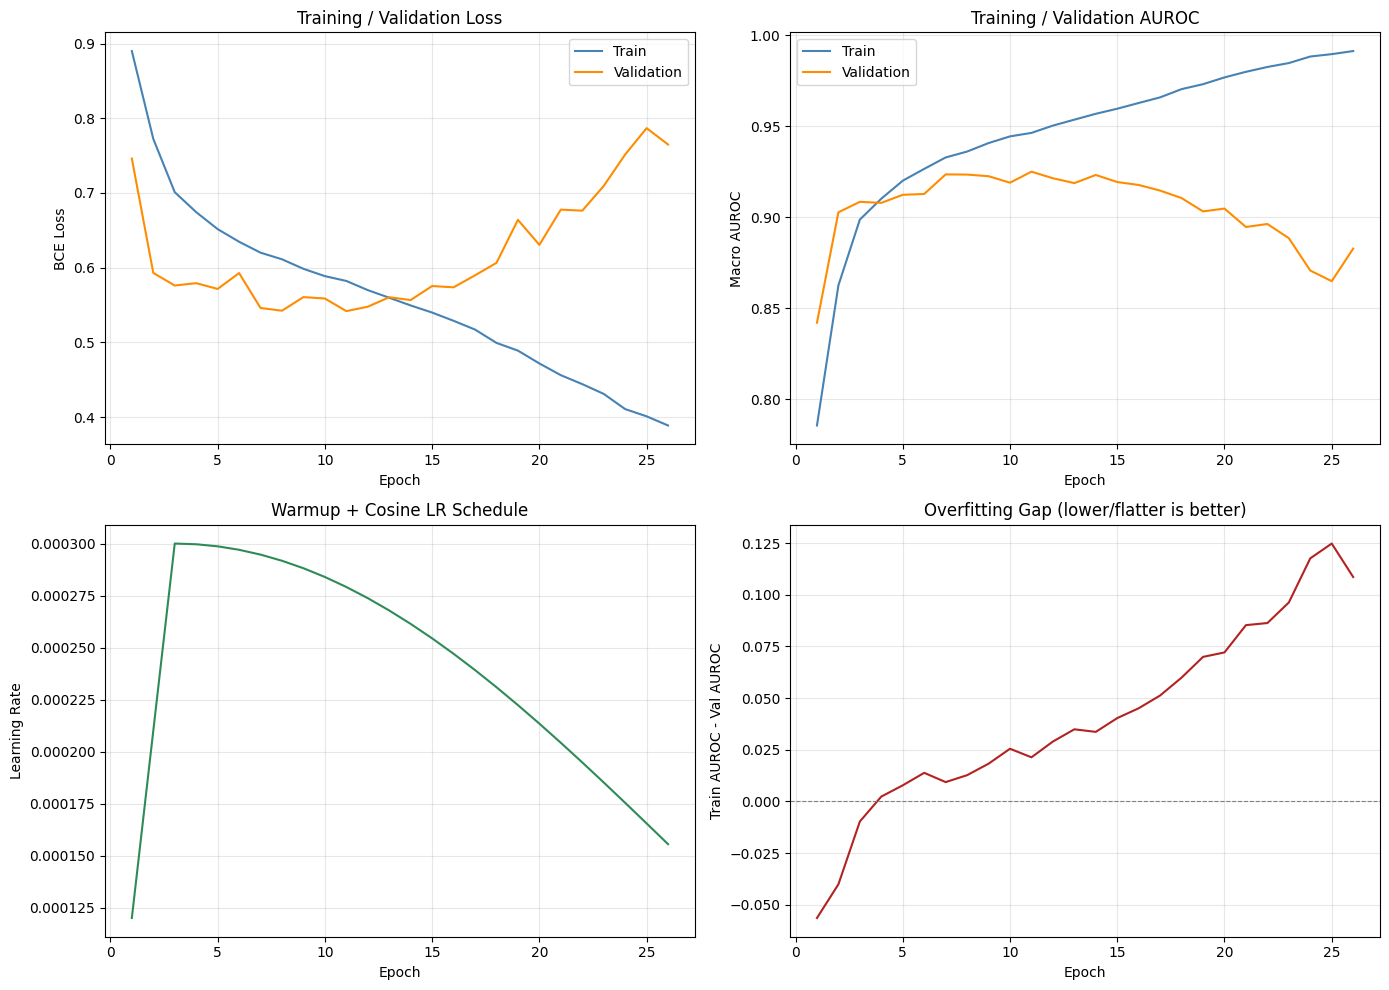

Best validation macro-AUROC: 0.9251 at epoch 11
Train-val AUROC gap at the final completed epoch: 0.1085


In [16]:
# Section 10 — Training Curves
# ---------------------------------------------------------------------------

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

axes[0, 0].plot(history_df["epoch"], history_df["train_loss"], label="Train", color="steelblue")
axes[0, 0].plot(history_df["epoch"], history_df["val_loss"], label="Validation", color="darkorange")
axes[0, 0].set_xlabel("Epoch")
axes[0, 0].set_ylabel("BCE Loss")
axes[0, 0].set_title("Training / Validation Loss")
axes[0, 0].legend()
axes[0, 0].grid(alpha=0.3)

axes[0, 1].plot(history_df["epoch"], history_df["train_auroc"], label="Train", color="steelblue")
axes[0, 1].plot(history_df["epoch"], history_df["val_auroc"], label="Validation", color="darkorange")
axes[0, 1].set_xlabel("Epoch")
axes[0, 1].set_ylabel("Macro AUROC")
axes[0, 1].set_title("Training / Validation AUROC")
axes[0, 1].legend()
axes[0, 1].grid(alpha=0.3)

axes[1, 0].plot(history_df["epoch"], history_df["learning_rate"], color="seagreen")
axes[1, 0].set_xlabel("Epoch")
axes[1, 0].set_ylabel("Learning Rate")
axes[1, 0].set_title("Warmup + Cosine LR Schedule")
axes[1, 0].grid(alpha=0.3)

# v2 new: explicit overfitting diagnostic - the train/val AUROC gap over time.
_gap = history_df["train_auroc"] - history_df["val_auroc"]
axes[1, 1].plot(history_df["epoch"], _gap, color="firebrick")
axes[1, 1].axhline(0, color="gray", linewidth=0.8, linestyle="--")
axes[1, 1].set_xlabel("Epoch")
axes[1, 1].set_ylabel("Train AUROC - Val AUROC")
axes[1, 1].set_title("Overfitting Gap (lower/flatter is better)")
axes[1, 1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(TRAIN_CONFIG.FIGURES_DIR, "10_training_curves.png"), dpi=300)
plt.show()

best_epoch = int(history_df.loc[history_df["val_auroc"].idxmax(), "epoch"])
best_val_auroc = float(history_df["val_auroc"].max())
final_gap = float(_gap.iloc[-1])
print(f"Best validation macro-AUROC: {best_val_auroc:.4f} at epoch {best_epoch}")
print(f"Train-val AUROC gap at the final completed epoch: {final_gap:.4f}")


## Section 11 — Per-Class Evaluation & Threshold Tuning (v2 new)

Macro-AUROC can hide a badly-performing minority class behind strong majority-class scores. This
section reloads the best checkpoint (`best_mamba.pth`, the epoch with peak validation macro-AUROC),
runs inference once over the validation set, and reports:

1. **Per-class AUROC and AUPRC** — AUPRC is more informative than AUROC for the rarer classes
   (HYP at 12.6% val prevalence), since AUROC can look deceptively good under heavy class imbalance.
2. **Per-class tuned decision thresholds** — instead of a blanket 0.5 cutoff, the threshold that
   maximizes F1 on the validation set is found independently for each class and saved to
   `thresholds.json` inside the checkpoint directory, for Notebook 06 to load and apply to the
   held-out test set.


In [17]:
# Section 11.1 — Reload best checkpoint and run inference on the validation set
# ---------------------------------------------------------------------------

_best_state = torch.load(checkpoint_manager.best_path, map_location=TRAIN_CONFIG.DEVICE)
model.load_state_dict(_best_state["model_state_dict"])
model.eval()
print(f"Loaded best checkpoint from epoch {_best_state['epoch']} for per-class evaluation.")

_all_probs, _all_labels = [], []
with torch.no_grad():
    for signals, labels, _ in tqdm(val_loader, desc="val inference", leave=False):
        signals = signals.to(TRAIN_CONFIG.DEVICE, non_blocking=True)
        with torch.amp.autocast(device_type="cuda", enabled=TRAIN_CONFIG.MIXED_PRECISION and torch.cuda.is_available()):
            logits = model(signals)
        _all_probs.append(torch.sigmoid(logits).float().cpu())
        _all_labels.append(labels.float())

val_probs = torch.cat(_all_probs, dim=0)     # (N_val, N_CLASSES)
val_labels = torch.cat(_all_labels, dim=0)   # (N_val, N_CLASSES)
print(f"Collected validation predictions: probs={tuple(val_probs.shape)}, labels={tuple(val_labels.shape)}")


Loaded best checkpoint from epoch 11 for per-class evaluation.


val inference:   0%|          | 0/34 [00:00<?, ?it/s]

Collected validation predictions: probs=(2156, 5), labels=(2156, 5)


,val_positive_rate_pct,auroc,auprc
NORM,44.389999,0.9436,0.9272
MI,25.230000,0.9275,0.8376
STTC,24.770000,0.9285,0.7900
CD,23.049999,0.9317,0.8608
HYP,12.570000,0.8942,0.6047


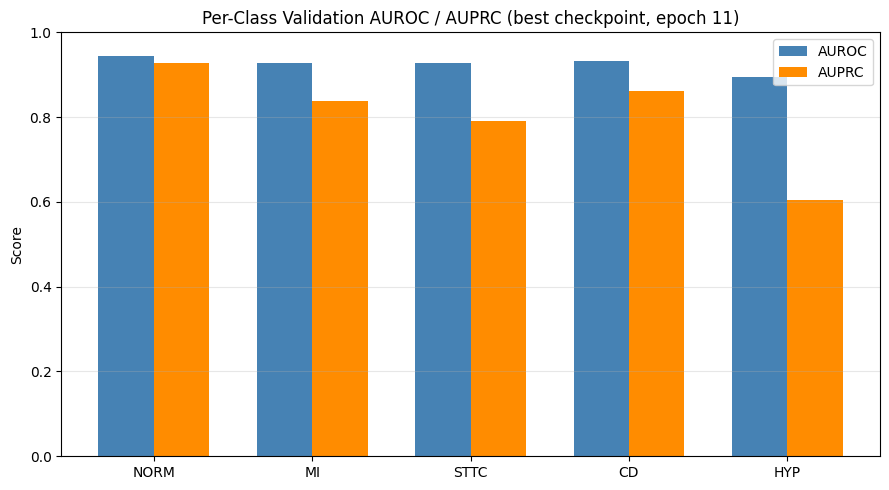

In [18]:
# Section 11.2 — Per-class AUROC / AUPRC
# ---------------------------------------------------------------------------

per_class_auroc_metric = MultilabelAUROC(num_labels=CONFIG.N_CLASSES, average=None).to("cpu")
per_class_auprc_metric = MultilabelAveragePrecision(num_labels=CONFIG.N_CLASSES, average=None).to("cpu")

per_class_auroc = per_class_auroc_metric(val_probs, val_labels.long()).numpy()
per_class_auprc = per_class_auprc_metric(val_probs, val_labels.long()).numpy()

per_class_table = pd.DataFrame({
    "val_positive_rate_pct": (val_labels.mean(dim=0).numpy() * 100).round(2),
    "auroc": per_class_auroc.round(4),
    "auprc": per_class_auprc.round(4),
}, index=CONFIG.SUPERCLASSES)
display(per_class_table)

fig, ax = plt.subplots(figsize=(9, 5))
x = np.arange(len(CONFIG.SUPERCLASSES))
width = 0.35
ax.bar(x - width / 2, per_class_auroc, width, label="AUROC", color="steelblue")
ax.bar(x + width / 2, per_class_auprc, width, label="AUPRC", color="darkorange")
ax.set_xticks(x)
ax.set_xticklabels(CONFIG.SUPERCLASSES)
ax.set_ylim(0, 1.0)
ax.set_ylabel("Score")
ax.set_title(f"Per-Class Validation AUROC / AUPRC (best checkpoint, epoch {_best_state['epoch']})")
ax.legend()
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(TRAIN_CONFIG.FIGURES_DIR, "11_per_class_auroc_auprc.png"), dpi=300)
plt.show()


In [19]:
# Section 11.3 — Per-class threshold tuning (maximize F1 on the validation set)
# ---------------------------------------------------------------------------

def tune_threshold_for_f1(probs: np.ndarray, labels: np.ndarray,
                           grid: np.ndarray = np.linspace(0.05, 0.95, 19)) -> Tuple[float, float]:
    """Grid-search the decision threshold maximizing F1 for one class.

    Parameters
    ----------
    probs : numpy.ndarray
        Predicted probabilities for one class, shape `(N,)`.
    labels : numpy.ndarray
        True binary labels for the same class, shape `(N,)`.
    grid : numpy.ndarray
        Candidate thresholds to evaluate.

    Returns
    -------
    tuple[float, float]
        `(best_threshold, best_f1)`.
    """
    best_threshold, best_f1 = 0.5, -1.0
    for t in grid:
        preds = (probs >= t).astype(int)
        f1 = f1_score(labels, preds, zero_division=0)
        if f1 > best_f1:
            best_threshold, best_f1 = float(t), float(f1)
    return best_threshold, best_f1


_val_probs_np = val_probs.numpy()
_val_labels_np = val_labels.numpy()

tuned_thresholds, tuned_f1s = {}, {}
for j, cls in enumerate(CONFIG.SUPERCLASSES):
    t, f1 = tune_threshold_for_f1(_val_probs_np[:, j], _val_labels_np[:, j])
    tuned_thresholds[cls] = t
    tuned_f1s[cls] = f1

threshold_table = pd.DataFrame({
    "tuned_threshold": pd.Series(tuned_thresholds),
    "f1_at_tuned_threshold": pd.Series(tuned_f1s).round(4),
    "f1_at_0.5": pd.Series({
        cls: f1_score(_val_labels_np[:, j], (_val_probs_np[:, j] >= 0.5).astype(int), zero_division=0)
        for j, cls in enumerate(CONFIG.SUPERCLASSES)
    }).round(4),
})
display(threshold_table)

_thresholds_path = os.path.join(TRAIN_CONFIG.CHECKPOINT_DIR, "thresholds.json")
with open(_thresholds_path, "w") as f:
    json.dump(tuned_thresholds, f, indent=2)
print(f"\nSaved per-class tuned thresholds -> {_thresholds_path}")
print("Notebook 06 should load this file and apply these thresholds to the held-out test set "
      "instead of a blanket 0.5 cutoff.")


,tuned_threshold,f1_at_tuned_threshold,f1_at_0.5
NORM,0.50,0.8532,0.8532
MI,0.50,0.7507,0.7507
STTC,0.40,0.7449,0.7423
CD,0.75,0.7850,0.7366
HYP,0.65,0.5686,0.5554



Saved per-class tuned thresholds -> ./mamba_supervised_v2_outputs_seed42/checkpoints/thresholds.json
Notebook 06 should load this file and apply these thresholds to the held-out test set instead of a blanket 0.5 cutoff.


## Section 12 — Notebook Summary

### Architecture (v2)
`MambaClassifier`: `Linear(N_LEADS -> EMBED_DIM)` input projection → `N_MAMBA_LAYERS` pre-norm
residual `BidirectionalMambaBlock`s (official `mamba_ssm.Mamba` run forward **and** backward per
block, concatenated and projected back to `d_model`) → `LayerNorm` → **mean pooling concatenated
with learned attention pooling** → `Dropout` → two-layer `ClassificationHead` → 5 multi-label
logits (NORM, MI, STTC, CD, HYP).

### What changed from v1, and why
See the comparison table in Section 0. In one sentence: v1 showed a widening train/val gap after
epoch ~8-10 (classic overfitting), so v2 adds regularization (dropout, weight decay, label
smoothing, tighter early stopping), fixes the class-imbalance blind spot in the loss (`pos_weight`),
and gives the model more useful capacity (bidirectional scanning, attention pooling) rather than
just training it for longer.

### Training results
See the printed per-epoch log above and the four-panel curves in Section 10 — including the new
train-val AUROC gap panel — for the exact trajectory and best epoch of this run. Section 11 reports
per-class AUROC/AUPRC and tuned decision thresholds for the best checkpoint.

### Checkpoint locations
| Artifact | Path |
|---|---|
| Best model (by val macro-AUROC) | `TRAIN_CONFIG.CHECKPOINT_DIR/best_mamba.pth` |
| Last checkpoint (resume-ready) | `TRAIN_CONFIG.CHECKPOINT_DIR/last_checkpoint.pth` |
| Per-epoch history | `TRAIN_CONFIG.CHECKPOINT_DIR/training_history.csv` |
| Frozen training config | `TRAIN_CONFIG.CHECKPOINT_DIR/config.json` |
| **Per-class tuned thresholds (v2 new)** | `TRAIN_CONFIG.CHECKPOINT_DIR/thresholds.json` |
| TensorBoard logs | `TRAIN_CONFIG.TENSORBOARD_DIR` |
| Figures (random ECG, training curves, per-class AUROC/AUPRC) | `TRAIN_CONFIG.FIGURES_DIR` |

### Does Notebook 02 (preprocessing) need to change?
**No.** Every v2 change made in this notebook is a training-time or model-time decision, not a
data-time one:

- `pos_weight` and label smoothing are properties of the **loss function**, computed here from
  `label_matrix` / `splits` that Notebook 02 already exposes — no new column, split, or signal
  transform is required from it.
- Bidirectional scanning and attention pooling are properties of the **model architecture** — they
  consume the exact same `(signal, label, ecg_id)` batches Notebook 02's `PTBXLClassificationDataset`
  already produces.
- Threshold tuning is a **post-hoc, inference-time** decision computed from validation predictions;
  it doesn't touch the data pipeline at all.

Notebook 02's job — official patient-stratified fold splitting, filtering, per-lead Z-score
normalization fit on the training fold only, padding/cropping, and the nine-operation augmentation
pipeline — is independent of which model or loss consumes its output, which is exactly the
separation of concerns it was designed for. The one thing worth double-checking in Notebook 02
(not changing) is that its augmentation probabilities/intensities are strong enough for your taste;
if you want heavier augmentation as an additional regularizer on top of the v2 changes here, that
is the one place it would be tuned, via `CONFIG.AUGMENTATION_PARAMS` — no structural change needed,
just parameter values.

### Next notebook
**Notebook 06 — Supervised Mamba Evaluation** loads `best_mamba.pth` and `thresholds.json`, and runs
the complete held-out evaluation this notebook deliberately excludes: test-set metrics (using the
tuned per-class thresholds, not 0.5), ROC/PR curves, the confusion matrix, t-SNE/PCA/UMAP embedding
visualization, explainability, error analysis, and the architecture comparison against Notebooks 03
(ResNet1D) and 04 (InceptionTime).
